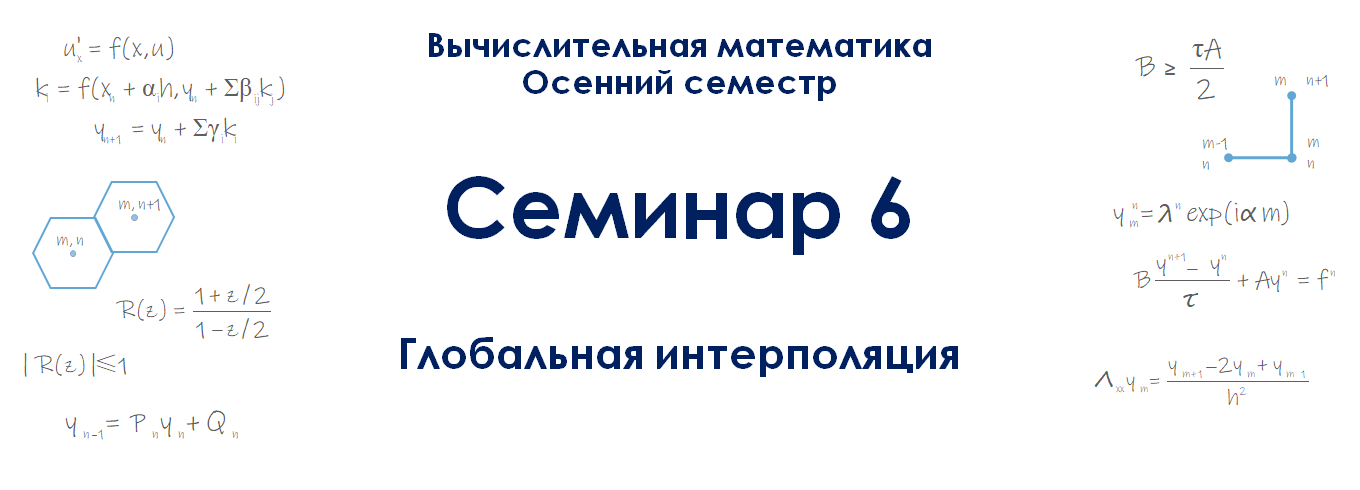

*Версия от 02.09.2026*

*Внимание! Семинар содержит интерактивные демонстрации. На сайте они представлены в статическом виде. Для работы интерактивных элементов необходимо скачать страницу в формате ipynb и запустить ipynb-файл локально.*

Перед изучением материалов семинара рекомендуем посетить лекцию или посмотреть видеозапись лекции. Ссылки (YouTube): [лекция 9](https://www.youtube.com/live/D1lAT1TLAv8?si=k2Wmd2gz_o6iO69_&t=2441) (начало темы), [лекция 10](https://www.youtube.com/live/TODavwxXtlU?si=OixRSBj-OXbIWhx4&t=15) (продолжение).

Предполагается, что читатель знает

* свойства интеграла Лебега (в общих чертах),
* конструкцию лебеговых пространств $L^p$ (в общих чертах) и классический пример такого пространства — пространство $L^2$,
* определение гильбертова пространства,
* теорему об обратной функции (для случая скалярной функции одного аргумента).
* теорему Ролля,
* определение $C$-нормы (равномерной нормы) $\Vert\cdot\Vert_C$ в пространстве $C^0[a,b]$, а также понятие равномерной сходимости функциональной последовательности,
* классификацию погрешностей вычислений.


# Введение

Одной из важнейших задач вычислительной математики является **задача приближения функций**. Не вдаваясь в строгие определения, можно сказать, что эта задача заключается в **подборе по данной функции** (скалярной или векторной, одной или нескольких переменных) **другой функции, которая в каком-то** (заранее определённом) **смысле была бы близка к первой функции**. Исключительную важность сформулированной проблемы легко понять из следующего наблюдения.

Очень многие математические задачи, встречающиеся на практике, могут быть записаны в **обобщённом виде**:

$$b=Fa.$$

Здесь предполагается, что $a$ и $b$ являются элементами некоторых (линейных) **функциональных пространств** (вообще говоря, различных): $a\in M_a$, $b\in M_b$, — а через $F$ обозначен некоторый **оператор** (часто тоже линейный), переводящий элементы пространства $M_a$ в элементы пространства $M_b$. Задача заключается в том, чтобы по известному $a$ найти $b$, либо, наоборот, по известному $b$ найти $a$. Конкретные свойства пространств $M_a$, $M_b$ (например, их конечномерность, гильбертовость, сепарабельность и пр.) и оператора $F$ (например, его компактность, самосопряжённость и пр.) зависят от рассматриваемой задачи.

Если подходить к задачам указанного типа **формально**, то можно сказать, что первая их разновидность (нахождение $b$ по $a$) вовсе и не нуждается в решении; задача "уже решена" в том смысле, что написано правило отыскания $b$ по заданному $a$: оно заключается в действии на этот элемент $a$ оператором $F$. Аналогично можно легко "решить" и обратную задачу (нахождение $a$ по $b$) — для этого достаточно обратить исходное равенство: $a=F^{-1}b$ (правда, дополнительно нужно разъяснить, какой смысл вкладывается в обозначение $F^{-1}$). Вся сложность заключается в том, что в подавляющем большинстве случаев, интересных с точки зрения практики, нельзя указать **конструктивный** (т.е. реально применимый) способ поиска образа $Fa$ в пространстве $M_b$ (или прообраза $F^{-1}b$ в пространстве $M_a$), а иногда затруднительно даже строго доказать, что поставленная **задача корректна и имеет единственное решение** (с теоретической точки зрения только после доказательства последнего утверждения имеет смысл браться за решение задачи). Другими словами, **сложность задачи связана именно с действием оператором** $F$ или $F^{-1}$ на элементы соответствующего пространства: **чем "сложнее устроены" пространства и операторы, тем труднее с ними работать**, поскольку может быть непонятно, какие именно процедуры и в каком порядке нужно осуществлять.

Суть любого численного метода, применяемого в задачах рассматриваемого вида, сводится к тому, что поставленная задача **заменяется другой (более простой) задачей**

$$\beta=\mathcal{F}\alpha,$$

в которой $\alpha$ и $\beta$ — элементы пространств $\mathcal{M}_\alpha$ и $\mathcal{M}_\beta$ (вообще говоря, отличающихся от $M_a$ и $M_b$) соответственно, а $\mathcal{F}$ — оператор (в общем случае тоже отличный от $F$), отображающий $\mathcal{M}_\alpha$ в $\mathcal{M}_\beta$. Замена задачи производится так, чтобы действие оператором $\mathcal{F}$ (или $\mathcal{F}^{-1}$) на элементы пространства $\mathcal{M}_\alpha$ (или $\mathcal{M}_\beta$) было **легко осуществимым в вычислительном плане**, т.е. чтобы это действие включало **конечное число каких-то элементарных операций** и чтобы его было сравнительно **нетрудно алгоритмизовать** — именно эти свойства "новой" задачи важны в свете реализации метода на компьютере. Кроме того, **необходимо, чтобы из близости** (в каком-то заранее определённом смысле) **данных** двух задач (скажем, операторов $F$ и $\mathcal{F}$, а также элементов $a\in M_a$ и $\alpha\in\mathcal{M}_\alpha$) **следовала близость** (возможно, уже в ином смысле) **искомых решений** (в приведённом примере — элементов $b\in M_b$ и $\beta\in\mathcal{M}_\beta$). В противном случае замена одной задачи другой, очевидно, лишена практической ценности.

**Вот тут-то и возникает потребность приближать одни функции другими**, поскольку **функции могут являться элементами рассматриваемых пространств или играть роль операторов, действующих между пространствами**.

На предыдущих семинарах мы рассмотрели уже по крайней мере две задачи, которые укладываются в приведённую общую схему: дифференцирование функций и решение систем линейных алгебраических уравнений. Правда, при постановке этих задач мы почти не подчёркивали их операторного характера, а при разборе численных методов не пользовались идеей приближения функций, хотя такой подход был вполне возможен. Например, формулы численного дифференцирования (см. семинар 1) можно было бы выводить не с помощью метода неопределённых коэффициентов, а путём действия оператором $D_k\equiv d^k/dx^k$ на какую-то функцию, заменяющую (приближающую в некотором смысле) исходную (табличную) функцию; именно так поступают во многих учебниках. Ещё одну задачу, допускающую операторную формулировку, мы рассмотрим в следующих семинарах, когда будем обсуждать **методы численного интегрирования**. Один из классов этих методов будет строиться именно с позиций приближения интегрируемых функций другими функциями (интерполянтами). Наконец, в операторных терминах формулируется вся **теория разностных схем**, а многие конкретные разностные схемы, применяемые для решения дифференциальных уравнений, строятся с использованием методов приближения функций (в качестве примера можно привести **интерполяционно-характеристические разностные схемы** для уравнения переноса, которые мы будем изучать в следующем семестре).

В нашем курсе уже рассматривались среднеквадратичные приближения, а далее мы будем подробно обсуждать **интерполяцию**. Другие способы (например, равномерные приближения) вследствие недостатка времени остаются за рамками наших семинаров.

# Постановка задачи интерполяции

В дальнейшем ради простоты и краткости обозначений мы рассматриваем случай **скалярных функций одной (вещественной) переменной**.

Напомним определения сетки, сеточной функции и сеточной проекции, которые мы давали на первом семинаре.

**Определение 1.** Будем говорить, что на отрезке $[a,b]$ введена *сетка*, если задано *конечное* множество

$$G=\{x_i\in\mathbb{R},\phantom{-}0\leq i\leq n:\phantom{-}a\leq x_0<x_1<\dots<x_n\leq b\}.$$

Точки $x_i$ будем называть *узлами сетки*, а величины $h_i=x_i-x_{i-1}$, $1\leq i\leq n$ — её *шагами*. Если $h_1=h_2=\dots=h_n\equiv h$, то сетка называется *равномерной*.

**Определение 2.** Пусть на отрезке $[a,b]$ введена сетка $G$. *Сеточной функцией* называется *конечное* множество пар

$$\mathscr{F}=\big\{(y,x):\phantom{-}y\in\mathbb{R},\phantom{-}x\in G\big\},$$

в котором каждое значение $x$ принадлежит *лишь одной паре*. Величины $f$ называются *значениями сеточной функции*.

**Определение 3.** Пусть дана функция $f\in L^p[a,b]$. *Проекцией* функции $f$ на сетку $G$ называется сеточная функция

$$\mathscr{F}_f=\big\{(f(x),x):\phantom{-}x\in G\big\},$$

где $G$ — некоторая сетка, введённая на отрезке $[a,b]$. Операция построения сеточной функции $\mathscr{F}_f$ по функции $f$ с помощью правила $y_i=f(x_i)$, $0\leq i\leq n$, называется *проектированием функции $f$ на сетку* (или сеточным проектированием).

Очевидно, что **при фиксированной сетке $G$** (заданной на отрезке $[a,b]$) **множество сеточных функций, построенных на этой сетке, представляет собой линейное пространство**; обозначим его через $\text{Gf}\,[a,b]$. Таким образом, проектирование некоторой гладкой функции на заданную сетку можно рассматривать как действие оператора $R$, отображающего элементы пространства $L^p[a,b]$ в элементы пространства $\text{Gf}\,[a,b]$ (по правилу $y_i=f(x_i)$). Часто при рассмотрении сеточного проектирования с этой точки зрения элементы пространства $L^p[a,b]$ называют **функциями-оригиналами**. Действие оператора $R$ заключается, образно говоря, в том, что он "обрезает" функцию-оригинал, "выкидывая" континуальные множества точек из областей её определения и значения.

На практике, как правило, полагают $p=2$, т.е. в качестве функций-оригиналов рассматривают элементы пространства $L^2[a,b]$, поэтому далее вместо $L^p[a,b]$ мы везде будем писать $L^2[a,b]$. Строго говоря, в роли элементов этого пространства (как и любого пространства $L^p[a,b]$) выступают не сами функции (измеримые по Лебегу), а **классы эквивалентности функций** (другими словами, множества $L^p[a,b]$ являются фактор-пространствами). Напомним, что норма в пространстве $L^2[a,b]$ порождается скалярным произведением: $\Vert f\Vert=\sqrt{(f,f)}$, где

$$(f,g)=\int\limits_{a}^{b}\mathop{dx}f(x)g(x)$$

(а метрика $\rho$ индуцируется этой нормой: $\rho(f, g)=\Vert f-g\Vert$). Здесь функции $f$ и $g$ предполагаются вещественнозначными, а интеграл понимается как интеграл Лебега. Хорошо известно, что **пространство** $L^2[a,b]$ (с указанным скалярным произведением) **является гильбертовым**. Отметим, что вместо отрезка $[a,b]$ везде выше можно было бы указывать произвольное множество $E$, измеримое по Лебегу.

Подчеркнём, что **отображение** $R$ из $L^2[a,b]$ в $\text{Gf}\,[a,b]$ **не является инъективным**. Иначе говоря, **одной и той же сеточной функции могут соответствовать разные функции-оригиналы**. Действительно, на сетке из узлов $x_n=\pi n$, где $n$ — целое неотрицательное число, не превосходящее $N\in\mathbb{N}$, можно определить, например, тождественно нулевую сеточную функцию (т.е. функцию, принимающую нулевые значения во всех узлах $x_n$). В качестве функций-оригиналов для этой сеточной функции могут выступать функции вида $f(x)=A\sin{x}$, поскольку $\sin x_n=0$. В данном примере одной и той же сеточной функции отвечает даже континуальное множество функций-оригиналов, поскольку $A\in\mathbb{R}$.

Наряду с оператором $R$, осуществляющим сеточное проектирование, естественно рассматривать также оператор $I$, переводящий элементы пространства $\text{Gf}\,[a,b]$ в элементы пространства $L^2[a,b]$. Функция, $\widetilde f\in L^2[a,b]$, поставленная оператором $I$ в соответствие сеточной функции $\mathscr{F}_f$, называется **функцией-образом**.

**Упражнение 1.** Являются ли операторы $R$ и $I$ линейными?

Подействуем на некоторый элемент $f\in L^2[a,b]$ сначала оператором $R$, а потом оператором $I$, т.е. совершим следующую цепочку преобразований:

$$f\in L^2[a,b]\quad\xrightarrow{R}\quad\mathscr{F}_f\in\text{Gf}\,[a,b]\quad\xrightarrow{I}\quad\widetilde f\in L^2[a,b].$$

Здесь функция-оригинал сначала была спроектирована на некоторую сетку $G$, а затем по полученной проекции была построена функция-образ. Можно сказать, что действие оператором $R$ "стёрло" часть информации о функции $f$, превратив её в элемент другого функционального пространства, а оператор $I$ восстановил функцию из исходного пространства, пользуясь информацией, сохранившейся в конечном числе точек. Ясно, что функция $\widetilde f$, вообще говоря, отличается от функции $f$, и можно ставить **вопрос о близости функции-оригинала и функции-образа**, т.е. выяснять, насколько успешным оказалось восстановление функции. С теоретической точки зрения этот вопрос решается вычислением расстояния между функциями $f$ и $\widetilde f$. Последнее возможно благодаря тому, что $f,\widetilde f\in L^2[a,b]$: выше мы отметили, что $\rho(f,\widetilde f)=\Vert f-\widetilde f\Vert$. Здесь не последнюю роль играют "хорошие" свойства пространства $L^2[a,b]$: в процессе теоретических построений (ими мы заниматься не будем) можно воспользоваться, например, его гильбертовостью.

На практике функции-оригиналы обычно неизвестны, и часто приходится иметь дело с **восстановлением функций по заданной сеточной функции**. Другими словами, отпадает первое преобразование из рассмотренной выше цепочки — требуется осуществить только второе из них:

$$\mathscr{F}_f\in\text{Gf}\,[a,b]\quad\xrightarrow{I}\quad\widetilde f\in L^2[a,b].$$

Очевидно, что при такой постановке вопроса нельзя оценить качество восстановления исходной функции $f\in L^2[a,b]$ оператором $I$ по предложенному выше способу: поскольку на практике обычно неизвестны ни функция $\widetilde f$, ни какие-либо её свойства, вычислить расстояние $\rho(f, \widetilde f)$ затруднительно. Сравнение же известных функций $\mathscr{F}_f$ и $\widetilde f$ лишено смысла, поскольку это **элементы разных функциональных пространств**.

Выход из указанного затруднения довольно очевиден. Можно спроектировать функцию $\widetilde f$ на заданную сетку (ту же, что и у функции $\mathscr{F}_f$) и сравнивать на предмет близости уже функции $\mathscr{F}_f$ и $\mathscr{F}_\tilde{f}$. Понятие близости двух сеточных функций (построенных на одной сетке) легко формализовать с помощью следующего определения.



**Определение 4.** Пусть $\mathscr{F},\mathscr{G}\in \text{Gf}\,[a,b]$, т.е.

$$\mathscr{F}=\big\{(y,x):\phantom{-}y\in\mathbb{R}, \phantom{-}x\in G\big\},\quad
  \mathscr{G}=\big\{(z,x):\phantom{-}z\in\mathbb{R},\phantom{-}x\in G\big\},$$

где $G$ — некоторая сетка, введённая на отрезке $[a,b]$ и содержащая $n+1$ узлов. *Вектором-разностью сеточных функций* $\mathscr{F}$ и $\mathscr{G}$ называется вектор длины $n+1$, составленный из разностей значений этих сеточных функций:

$$\text{vec}(\mathscr{F}-\mathscr{G})\equiv
  \begin{pmatrix}
    y_0-z_0 & y_1-z_1 & \dots & y_n-z_n
  \end{pmatrix}^\text{T}.$$

Очевидно, что, имея в виду определение 4, легко ввести метрику в пространстве $\text{Gf}\,[a,b]$ — достаточно положить $\rho(\mathscr{F},\mathscr{G})=\Vert\text{vec}(\mathscr{F}-\mathscr{G})\Vert$, где $\Vert\cdot\Vert$ — произвольная векторная норма в пространстве $\mathbb{R}^{n+1}$.

**Упражнение 2.** Убедитесь, что предложенная функция $\rho$ действительно является метрикой на $\text{Gf}\,[a,b]$.

На практике обычно считают, что сеточные функции $\mathscr{F}$ и $\mathscr{G}$ близки, если $\rho(\mathscr{F},\mathscr{G})=0$, т.е. проще говоря, если вектор-разность $\text{vec}(\mathscr{F}- \mathscr{G})$ равен нулевому вектору.

Вернёмся к задаче восстановления функции-образа по известной сеточной функции и выпишем всю цепочку действий операторами $R$ и $I$ (включая и первое преобразование с неизвестной функцией $f\in L^2[a,b]$):

$$f\in L^2[a,b]\quad\xrightarrow{R}\quad\mathscr{F}_f\in\text{Gf}\,[a,b]\quad\xrightarrow{I}\quad\widetilde f\in L^2[a,b]\quad\xrightarrow{R}\quad \mathscr{F}_\tilde{f}\in\text{Gf}\,[a,b].$$

С учётом сказанного выше, условимся считать задачу восстановления функции $\widetilde{f}$ оператором $I$ по функции $\mathscr{F}_f$ решённой, если $\rho(\mathscr{F}_f,\mathscr{F}_\tilde{f})=0$. Другими словами, в узлах сетки $G$, введённой на отрезке $[a,b]$, значения функций $\widetilde{f}$ и $\mathscr{F}_f$ должны совпадать. Поставленная задача называется **задачей глобальной точной интерполяции**. Оператор $I$ часто называется **оператором интерполяции**, а функцию-образ $\widetilde{f}$ ещё называют **интерполянтом**. Отметим, что термином "интерполяция" принято пользоваться в тех случаях, когда граничные точки сетки $G$, введённой на отрезке $[a,b]$, совпадают с граничными точками этого отрезка, т.е. когда **функция восстанавливается только в точках, лежащих между какими-либо двумя узлами заданной сетки**. Если это требование не выпонено (т.е. функция восстанавливается "за пределами" сетки), то говорят об **экстраполяции**.

Подчеркнём, что из требования $\rho(\mathscr{F}_f,\mathscr{F}_\tilde{f})=0$, которое мы положили в основу формулировки задачи интерполяции, не следует, вообще говоря, никакой информации о величине $\rho(f,\widetilde{f})$. В самом деле, в силу свойств интеграла Лебега расстояние $\rho(f,\widetilde{f})$ не меняется при изменении функций $f$ и $\widetilde{f}$ на множестве лебеговой меры нуль (а любое конечное множество точек отрезка $[a,b]$ имеет как раз меру нуль). Значит, всегда можно "подогнать" значения функций $f$ и $\widetilde{f}$ так, чтобы условие $\rho(\mathscr{F}_f,\mathscr{F}_\tilde{f})=0$ выполнилось, не изменив при этом величины $\rho(f,\widetilde{f})$.

Другими словами, **близость сеточных проекций функции-оригинала и функции-образа ещё не влечёт близости самих функции-оригинала и функции-образа**. В связи с этим обычно утверждают, что **задача интерполяции некорректна**. Грубо говоря, это значит, что **если некоторая функция $\widetilde f$ повторяет неизвестную функцию $f$ в конечном числе точек, то отсюда ещё не следует, что функция $\widetilde f$ "хорошо приближает" функцию $f$**.

В отдельных случаях некоторые сведения о функции-оригинале всё-таки известны. Например, может быть известно, что функция-оригинал $f$ является гладкой. Иногда могут быть доступны значения производных функции $f$. Существенен также сам способ задания её сеточной проекции $\mathscr{F}_f$: в одних случаях узлы сетки могут быть зафиксированными, а в других случаях может быть доступно вычисление значений функции $f$ в произвольно выбранных узлах. Учёт этих (и других) особенностей позволяет конструировать различные способы интерполяции, улучшающие (в некоторым смысле) приближение функции-оригинала $f$ функцией-образом $\widetilde{f}$.

Наряду с задачей **глобальной интерполяции**, сформулированной выше, рассматривается также задача **локальной интерполяции**. Если в первом случае, как мы видели, интерполянт задаётся **сразу на всём отрезке** $[a,b]$, то во втором случае для каждого подотрезка $[x_i,x_{i+1}]$, образованного узлами сетки, строится свой (локальный) интерполянт, а в узлах сетки осуществляется **сшивка** полученных интерполянтов (по возможности, гладкая). Иначе говоря, **при локальной интерполяции функция-образ задаётся на отрезке $[a,b]$ кусочно** (по-возможности, кусочно-гладко). Локальную интерполяцию называют ещё интерполяцией **сплайнами** (ранее английский термин "spline" означал гибкую чертёжную линейку, которой пользовались для графического кусочно-гладкого интерполирования функций). О сплайнах мы будем говорить на следующем семинаре.

# Алгебраическая интерполяция

Наиболее простой способ глобальной интерполяции на отрезке $[a,b]$ сводится к составлению по сеточной функции $\mathscr{F}_f$ **обобщённого полинома**

$$\widetilde f=\sum\limits_{k=0}^n c_k\varphi_k(x),$$

в котором $c_k$ — числовые коэффициенты, а $\varphi_k(x)$ — некоторая система функций, определённых на отрезке $[a,b]$. Функции $\varphi_k$ часто называются **базисными функциями**.

**Условие интерполяционности** $y_i=\widetilde{f}(x_i)$ (здесь $y_i$ — значения сеточной функции $\mathscr{F}_f$) принимает вид СЛАУ на коэффициенты $c_k$:

$$\sum\limits_{k=0}^n c_k\varphi_k(x_i)=y_i,\quad 0\leq i\leq n.$$

Введя те же обозначения, что и при рассмотрении МНК (см. семинар 5):

$$\begin{gather}
  \textbf{c}=\big(c_0,\,c_2,\,\dots,\,c_n\big)^\text{T};\quad \textbf{y}=\big(y_0,\,y_2,\,\dots,\,y_n\big)^\text{T};\\[0.2cm]
  \boldsymbol{\varphi}_k=\big(\varphi_k(x_0),\,\varphi_k(x_2),\,\dots,\,\varphi_k(x_n)\big)^\text{T},\quad 0\leq k\leq n;\\[0.2cm]
  \textbf{G}_\varphi=(g_{ik}),\quad g_{ik}=\varphi_k(x_i),\quad 0\leq i,\,k\leq n,
  \end{gather}$$

можно переписать получившуюся СЛАУ в векторно-матричной форме:

$$\textbf{G}_\varphi\textbf{c}=\textbf{y}.$$

Подчеркнём, что в данном случае (в отличие от случая МНК) матрица $\textbf{G}_\varphi$ является квадратной (и имеет порядок $n+1$).

Как известно, СЛАУ $\textbf{G}_\varphi\textbf{c}=\textbf{y}$ имеет единственное решение, если система столбцов $\boldsymbol{\varphi}_k$ является **линейно независимой**. На пятом семинаре мы видели, что это условие выполнено при любом выборе узлов сетки, если в качестве базисных функций выбраны мономы $\boldsymbol{\varphi}_k(x)=x^k$, $0\leq k\leq n$. В этом случае обобщённый полином принимает вид **алгебраического полинома**

$$\widetilde{f}=\sum_{k=0}^{n} c_k x^{k}\equiv P_n(x)$$

и сама интерполяция называется алгебраической. Таким образом, справедлива теорема.

**Теорема 1.** Для сеточной функции $\mathscr{F}_f\in\text{Gf}\,[a,b]$, заданной в $n+1$ узлах, существует *единственный* алгебраический полином

$$P_n(x)=\sum_{k=0}^{n} c_k x^{k}$$

степени не выше $n$, решающий задачу глобальной точной интерполяции на отрезке $[a,b]$, т.е. обеспечивающий выполнение *условия интерполяционности*

$$y_i=P_n(x_i),\quad 0\leq i\leq n.$$

Здесь $y_i$ — значения функции $\mathscr{F}_f$.

Как видим, для осуществления алгебраической интерполяции достаточно найти коэффициенты $c_k$ путём решения СЛАУ $\textbf{G}_\varphi\textbf{c}=\textbf{y}.$ Однако, как уже отмечалось на семинаре 5, при больших $n$ эта СЛАУ оказывается очень плохо обусловленной. Поэтому на практике алгебраические интерполянты строят иначе. Мы рассмотрим **две возможные формы записи интерполяционных полинов: Лагранжа и Ньютона**.

## Интерполяционный полином в форме Лагранжа

Пусть на отрезке $[a,b]$ введена сетка с узлами $\big\{x_i\big\}_{i=0}^n$. Определим на том же отрезке **вспомогательные функции** $\ell_i(x)$:

$$\ell_i(x)=\prod_{\substack{k=0 \\ k\ne i}}^{n}\frac{x-x_k}{\,x_i-x_k\,},\quad 0\leq i\leq n.$$

Легко видеть, что они представляют собой многочлены степени $n$, причём $\ell_i(x_j)=\delta_{ij}$. Именно последнее свойство позволяет легко записать интерполяционный полином:

$$P_n(x)=\sum_{i=0}^{n} y_i\,\ell_i(x).$$

Условие интерполяционности (см. теорему 1), очевидно, удовлетворяется:

$$P_n(x_j)=\sum_{i=0}^{n} y_i\,\ell_i(x_j)=\sum_{i=0}^{n} y_i\,\delta_{ij}=y_j,\quad 0\leq j\leq n.$$

Иногда интерполяционный полином в форме Лагранжа записывают несколько иначе: вводят функцию

$$\omega(x)=\prod_{k=0}^{n}(x-x_k)$$

и замечают, что

$$\ell_i(x)=\frac{\omega(x)}{(x-x_i)\cdot\omega'(x_i)}.$$

Тогда

$$P_n(x)=\sum_{i=0}^{n} \frac{y_i\cdot\omega(x)}{(x-x_i)\cdot\omega'(x_i)}.$$

**Упражнение 3.** Докажите равенство

$$\ell_i(x)=\frac{\omega(x)}{(x-x_i)\cdot\omega'(x_i)}.$$

## Задача 1

Для сеточной функции

$$
\begin{array}{c|cccc}
  x_i & -3 & -2 & -1 & 0 \\
  \hline
  y_i & 16 & 7 & 4 & 1
\end{array}
$$

построить интерполяционный полином в форме Лагранжа.

**Решение.** Интерполяционный полином в форме Лагранжа имеет следующий вид:

$$P_3(x)=\sum_\limits{i=0}^3 y_i\,\ell_i(x).$$

Ясно, что в данном случае это многочлен степени не выше третьей, поскольку каждая из вспомогательных функций $\ell_i$ есть алгебраический полином степени $n$, а из условия задачи следует, что $n=3$, так как нумерацию узлов сетки мы начинаем с нуля (всего узлов четыре).

Выпишем вспомогательные функции:

$$
\begin{gather}
  \ell_0(x)=
  \prod_{\substack{k=0 \\ k\neq 0}}^{3}\frac{x-x_k}{\,x_0-x_k\,}=
  \frac{(x-x_1)(x-x_2)(x-x_3)}{(x_0-x_1)(x_0-x_2)(x_0-x_3)}=
  \frac{(x+2)(x+1)(x-0)}{(-3+2)(-3+1)(-3-0)}
=-\frac{x^3}{6}-\frac{x^2}{2}-\frac{x}{3};\\[0.2cm]
  \ell_1(x)=
  \prod_{\substack{k=0 \\ k\neq 1}}^{3}\frac{x-x_k}{\,x_1-x_k\,}=
  \frac{(x-x_0)(x-x_2)(x-x_3)}{(x_1-x_0)(x_1-x_2)(x_1-x_3)}=
  \frac{(x+3)(x+1)(x-0)}{(-2+3)(-2+1)(-2-0)}=
  \frac{x^3}{2}+2x^2+\frac{3}{2}x;\\[0.2cm]
  \ell_2(x)=
  \prod_{\substack{k=0 \\ k\neq 2}}^{3}\frac{x-x_k}{\,x_2-x_k\,}=
  \frac{(x-x_0)(x-x_1)(x-x_3)}{(x_2-x_0)(x_2-x_1)(x_2-x_3)}=
  \frac{(x+3)(x+2)(x-0)}{(-1+3)(-1+2)(-1-0)}=
  -\frac{x^3}{2}-\frac{5}{2}x^2-3x;\\[0.2cm]
  \ell_3(x)=
  \prod_{\substack{k=0 \\ k\neq 3}}^{3}\frac{x-x_k}{\,x_3-x_k\,}=
  \frac{(x-x_0)(x-x_1)(x-x_2)}{(x_3-x_0)(x_3-x_1)(x_3-x_2)}=
  \frac{(x+3)(x+2)(x+1)}{(0+3)(0+2)(0+1)}
  =\frac{x^3}{6}+x^2+\frac{11}{6}x+1.
\end{gather}
$$

Подставляя значения сеточной функции $y_i$ и найденные вспомогательные функции $\ell_i$ в формулу для $P_3$, получаем искомый интерполяционный полином:

$$P_3(x)=16\,\ell_0(x)+7\,\ell_1(x)+4\,\ell_2(x)+\ell_3(x)=-x^3-3x^2-5x+1.$$


Те же действия можно было бы выполнить с помощью функции ```interpolating_poly``` библиотеки ```sympy``` ([документация](https://docs.sympy.org/latest/modules/polys/reference.html#sympy.polys.specialpolys.interpolating_poly)). Эта функция принимает на вход количество узлов сетки ```n``` (указывается именно **количество**, а не наибольший номер узла, т.е. в нашем случае ```n=4```), независимую переменную ```x``` и таблицу значений сеточной функции в виде списков ```X``` и ```Y```. Возвращается интерполяционный полином в форме Лагранжа (объект класса ```Poly```):

In [34]:
from sympy import symbols, interpolating_poly

x = symbols('x')
poly_Lagr = interpolating_poly(n=4, x=x, X=[-3, -2, -1, 0], Y=[16, 7, 4, 1])
poly_Lagr

-8*x*(x + 1)*(x + 2)/3 + 7*x*(x + 1)*(x + 3)/2 - 2*x*(x + 2)*(x + 3) + (x + 1)*(x + 2)*(x + 3)/6

Упростить полином, представив его в виде суммы мономов (т.е. "собрать" коэффициенты при степенях аргумента), можно с помощью функции ```expand``` ([документация](https://docs.sympy.org/latest/tutorials/intro-tutorial/simplification.html#expand)):

In [35]:
from sympy import expand

expand(poly_Lagr)

-x**3 - 3*x**2 - 5*x + 1

## Интерполяционный полином в форме Ньютона

Интерполяционный полином в форме Лагранжа удобен для теоретических построений, но его не очень удобно строить на практике — получаются громоздкие выкладки. Поэтому при вычислениях часто пользуются интерполяционным полиномом в форме Ньютона. Для его записи необходимо ввести понятие **разделённых разностей**. Они определяются рекуррентно.

**Определение 5.** Пусть на отрезке $[a,b]$ введена сетка $G$, состоящая из $n+1$ узлов, и определена функция $f=f(x)$. Тогда

*  разделёнными разностями *нулевого порядка* называются значения функции $f$ в узлах сетки (в количестве $n+1$):

   $$f(x_i)\equiv f(x_i),\quad 0\leq i\leq n;$$

*  разделёнными разностями *первого порядка* называются отношения (в количестве $n$):

   $$f(x_i,\,x_{i+1})\equiv\frac{f(x_{i+1})-f(x_i)}{x_{i+1}-x_{i}},\quad 0\leq i\leq n-1;$$

*  разделёнными разностями *второго порядка* называются отношения (в количестве $n-1$):

   $$f(x_i,\,x_{i+1},\,x_{i+2})\equiv\frac{f(x_{i+1},\,x_{i+2})-f(x_{i},x_{i+1})}{x_{i+2}-x_{i}},\quad 0\leq i\leq n-2;$$

*  наконец, разделёнными разностями *$k$-го порядка* называются отношения (в количестве $n-k+1$):

   $$f(x_i,\,x_{i+1},\,\dots,\,x_{i+k})\equiv\frac{f(x_{i+1},\,\dots,\,x_{i+k})-f(x_{i},\,\dots,\,x_{i+k-1})}{x_{i+k}-x_{i}},\quad 0\leq i\leq n-k.$$

Из определения ясно, что **на сетке из $n+1$ узла можно построить разделённые разности вплоть до $n$-го порядка включительно, причём разность наивысшего порядка будет всего одна**.

Можно показать, что любая разделённая разность является симметричной функцией своих аргументов, т.е. не изменяется при их перестановке. Кроме того, оказывается, что существует точка $\xi\in [a,b]$ такая что,

$$f(x_i,\,x_{i+1},\,\dots,\,x_{i+k})=\frac{f^{(k)}(\xi)}{k!}$$

(разумеется, если функция $f$ является $k$ раз дифференцируемой).

Введём для "первых" (т.е. получающихся при $i=0$) разностей каждого порядка обозначения:

$$\Delta_0=f(x_0),\quad \Delta_1=f(x_0,\,x_1),\quad\dots,\quad \Delta_k=f(x_0,\,\dots\,x_k),\quad\dots$$

(иногда ради краткости их используют для обозначения произвольных разделённых разностей, а не только "первых"). Тогда интерполяционный полином в форме Ньютона можно записать так:

$$\begin{align}
  P_n(x)&=\Delta_0+\Delta_1(x-x_0)+\Delta_2(x-x_0)(x-x_1)+\dots+\Delta_n(x-x_0)\dots(x-x_{n-1})=\\[0.2cm]
 &=\sum\limits_{k=0}^n\Delta_k\cdot\prod\limits_{j=0}^{k-1}(x-x_j).
  \end{align}$$

Существует и другой способ его записи, для которого вводятся "последние" разделённые разности

$$\widetilde\Delta_0=f(x_n),\quad \widetilde\Delta_1=f(x_{n-1},\,x_n),\quad\dots,\quad \widetilde\Delta_k=f(x_{n-k},\,\dots\,x_n),\quad\dots\,.$$

Тогда

$$\begin{align}
  P_n(x)&=\widetilde\Delta_0+\widetilde\Delta_1(x-x_n)+\widetilde\Delta_2(x-x_n)(x-x_{n-1})+\dots+\widetilde\Delta_n(x-x_n)\dots(x-x_{1})=\\[0.2cm]
 &=\sum\limits_{k=0}^n\widetilde\Delta_k\cdot\prod\limits_{j=n-k+1}^{n}(x-x_j).
  \end{align}$$

Чтобы различать эти формы записи, первую называют полиномом **"вперёд"**, а вторую — полиномом **"назад"**.

Упомянутая выше связь разделённых разностей и производных позволяет считать интерполяционный полином в форме Ньютона **разностным аналогом формулы Тейлора**.

Выполнение условия интерполяционности для полинома в форме Ньютона неочевидно — его приходится специально доказывать (например, по индукции). Зато на практике полином в форме Ньютона более удобен, например, тем, что при добавлении узлов в сетку не требуется полностью перестраивать весь полином (как это пришлось бы делать при записи в форме Лагранжа): достаточно добавить к уже имеющемуся полиному несколько слагаемых.

На практике для построения интерполяционного полинома в форме Ньютона составляют **таблицу разделённых разностей**. Мы покажем, как это делается, на примере следующей задачи.

## Задача 2

Для сеточной функции

$$
\begin{array}{c|cccc}
  x_i & -3 & -2 & -1 & 0 \\
  \hline
  y_i & 16 & 7 & 4 & 1
\end{array}
$$

(той же, что и в задаче 1) построить интерполяционный полином в форме Ньютона. Найти значение функции в точке $x=-2,5$, используя линейную, квадратичную  и кубическую интерполяцию. Вычислить (приближённо) производную функции в граничных узлах сетки.

**Решение.** Построим таблицу разделённых разностей (см. рисунок).

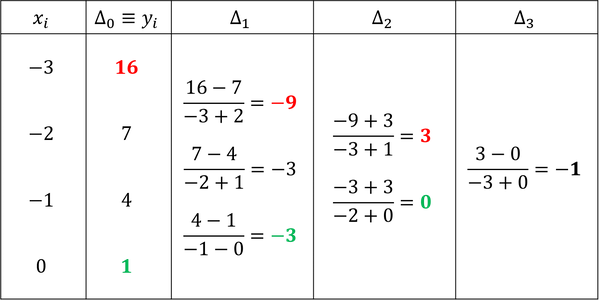

*Таблица разделённых разностей к решению задачи 2*

В соответствии с приведённым выше определением, каждая разделённая разность из таблицы получается составлением дифференциального отношения для разностей предыдущего порядка, причём **база (т.е. делитель) дифференциального отношения всегда берётся максимально широкой**. Например, при составлении первой из величин $\Delta_2$ мы взяли разность "соседних" величин $\Delta_1$ (т.е. $-9-(-3)=-9+3=-6$) и поделили её именно на **максимально широкую** базу $x_0-x_2$ (т.е. на $-3-(-1)=-3+1=-2$), а не на базы $x_0-x_1$ или $x_1-x_2$, которые можно было бы составить из узлов, задействованных при вычислении рассматриваемых разностей $\Delta_1$.

Остаётся выписать интерполяционный полином в форме Ньютона, двигаясь по верхней (красные числа) или нижней (зелёные числа) косым строкам таблицы. Значение $-1$ разделённой разности $\Delta_3$ (выделено жирным шрифтом) входит в оба варианта полинома (поэтому оно и не выделено ни красным, ни зелёным цветом).

Итак, первый вариант записи (красные числа) — **полином "вперёд"**:

$$\begin{gather}
  P_3(x)=\Delta_0+\Delta_1\cdot(x-x_0)+\Delta_2\cdot(x-x_0)(x-x_1)+\Delta_3\cdot(x-x_0)(x-x_1)(x-x_2)=\\
  =16-9\cdot(x+3)+3\cdot(x+3)(x+2)-1\cdot(x+3)(x+2)(x+1);
  \end{gather}$$

второй вариант записи (зелёные числа) — **полином "назад"** (напомним, что у нас $n=3$):

$$\begin{gather}
  P_3(x)=\widetilde\Delta_0+\widetilde\Delta_1\cdot(x-x_{n-0})+\widetilde\Delta_2\cdot(x-x_{n-0})(x-x_{n-1})+\widetilde\Delta_3\cdot(x-x_{n-0})(x-x_{n-1})(x-x_{n-2})=\\
  =1-3\cdot(x-0)+0\cdot(x-0)(x+1)-1\cdot(x-0)(x+1)(x+2).
  \end{gather}$$

Упростив эти два полинома, легко убедиться в том, что они, как и положено, совпадают и друг с другом, и с интерполяционным полиномом Лагранжа, построенным при решении задачи 1:

$$P_3(x)=-x^3-3x^2-5x+1.$$

Сразу можно вычислить искомые значения производной:

$$P_3'(x)=-3x^2-6x-5,\quad P_3'(-3)=-14,\quad P_3'(0)=-5.$$

Подчеркнём, что значения производной в граничных точках сетки можно было бы быстро вычислить и без предварительного упрощения полинома. Чтобы найти производную в **правой** граничной точке, надо взять полином **"назад"**, отбросить его свободный член, выкинуть из каждого слагаемого скобку, зануляющуюся при подстановке правой граничной точки, и найти значение полученного полинома в этой точке. Иначе говоря,

$$P'(0)=\big[-3+0\cdot(x+1)-1\cdot(x+1)(x+2)\big]_{x=0}=-5.$$

В квадратных скобках мы переписали приведённый выше полином "назад", проигнорировав его свободный член и скобку $(x-0)$ в каждом слагаемом (так как в правой граничной точке она зануляется).

Аналогичное правило справедливо и для вычисления значения производной в **левом** граничном узле: надо взять полином **"вперёд"** без свободного члена, отбросить скобку, зануляющуюся на левой границе, и найти значение получившегося полинома. В нашем примере:

$$P'(-3)=\big[-9+3\cdot(x+2)-1\cdot(x+2)(x+1)\big]_{x=-3}=-14.$$

**Упражнение 4.** Обоснуйте упомянутые правила быстрого вычисления производных в граничных точках.

Требуемую по условию задачи кубическую интерполяцию мы построили: $P_3(x)=-x^3-3x^2-5x+1$. Для построения квадратичной интерполяции, надо выбросить из полинома слагаемое с разделённой разностью третьего порядка $\Delta_3$. Ориентируясь на полином "вперёд", получаем:

$$P_2(x)=16-9\cdot(x+3)+3\cdot(x+3)(x+2)=3x^2+6x+7.$$

Аналогично получаем линейную интерполяцию (отбрасываем разделённые разности $\Delta_2$ и $\Delta_3$):

$$P_1(x)=16-9\cdot(x+3)=-9x-11.$$

Таким образом,

$$P_3(-2,5)=10,375,\quad P_2(-2,5)=10,75,\quad P_1(-2,5)=11,5.$$

В дополнение к предложенному аналитическому решению напишем функцию ```diffs_table```, вычисляющую таблицу разделённых разностей по таблице значений сеточной функции (заданной в виде двух массивов):

In [36]:
import numpy as np

def diffs_table(x: np.ndarray, y: np.ndarray):
    k = len(y) # количество узлов сетки (совпадает с количеством разделённых разностей)
    diffs = np.zeros([k, k])
    diffs[:, 0] = y # нулевые разделённые разности - значения самой сеточной функции

    for j in range(1, k):
        for i in range(k-j):
            diffs[i, j] = (diffs[i+1, j-1] - diffs[i, j-1]) / (x[i+j] - x[i])

    return diffs

Протестируем функцию на примере из задачи:

In [37]:
x = [-3, -2, -1, 0]
y = [16,  7,  4, 1]

diffs_table(x, y)

array([[16., -9.,  3., -1.],
       [ 7., -3.,  0.,  0.],
       [ 4., -3.,  0.,  0.],
       [ 1.,  0.,  0.,  0.]])

Как видим, таблица строится правильно, хотя и не очень наглядно: в каждом столбце разности "сдвинуты вверх", так что $j$-й столбец содержит $n+1-j$ разделённых разностей $j$-го порядка в первых $n+1-j$ строках ($0\leq j\leq n$).

Используя функцию ```diffs_table```, можно написать программу, вычисляющую значение интерполяционного полинома в форме Ньютона в произвольной точке $\xi$. Для определённости будем строить полином "вперёд":

In [38]:
def Newton_poly_forward(x: np.ndarray, y: np.ndarray, xi: float):
    diffs = diffs_table(x, y) # строим таблицу разделённых разностей

    coeffs = diffs[0, :] # коэффициенты - первая строка таблицы
    x_factors = [1]

    for i in range(0, len(coeffs)-1):
        x_factors.append(x_factors[-1]*(xi - x[i]))

    return coeffs @ x_factors

С помощью этой программы можно проверить полученное при решении задачи равенство $P_3(-2,5)=10,375$:

In [39]:
float(Newton_poly_forward(x, y, -2.5))

10.375

**Упражнение 5.** Так ли хороша предложенная программа? Какие проблемы могут возникнуть при её использовании?

*Указание.* Как в написанной программе вычисляется значение интерполяционного полинома в заданной точке $\xi$? См. также численную демонстрацию с полиномами Чебышёва из раздела "МНК в Python" семинара 5.

**Упражнение 6.** Напишите аналогичную функцию ```Newton_poly_backward```, вычисляющую значение полинома "назад" в произвольной точке $\xi$.

Функция ```Newton_poly_forward``` позволяет легко визуализировать построенный кубический полином $P_3$:

In [40]:
import matplotlib.pyplot as plt

def graph_Newton(x: np.ndarray, y: np.ndarray):
    func = lambda xi: Newton_poly_forward(x, y, xi)
    func = np.vectorize(func)

    grid = np.arange(np.min(x), np.max(x) + 0.01, 0.01)
    P = func(grid)

    fig, ax = plt.subplots()
    ax.scatter(x, y, color='blue')
    ax.plot(grid, P, color='red')

    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")

    plt.title("Интерполяционный полином в форме Ньютона")

    plt.show()

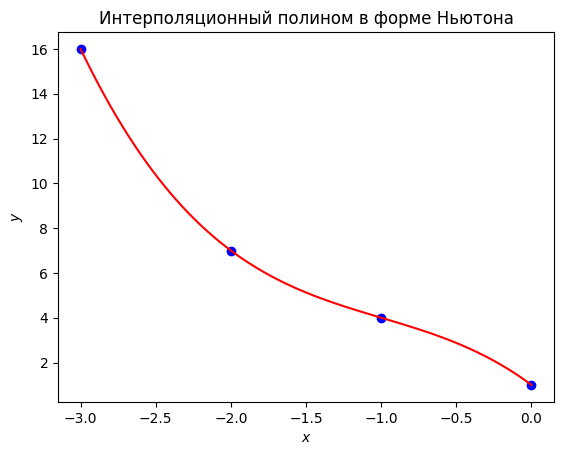

In [41]:
graph_Newton(x, y)

Любопытно вернуться к примеру из первого семинара (см. раздел "Введение", подраздел "Пример 2"), в котором демонстрировалась плохая обусловленность задачи неточной интерполяции, решавшейся методом наименьших квадратов, и повторить аналогичную демонстрацию, но уже с функцией ```Newton_poly_forward```. Напомним, что суть примера состоит в интерполяции сеточной функции $\mathscr{F}_n$ со случайными значениями (и вполне определёнными узлами) при различных $n$. Составим соответствующую программу:

In [42]:
from ipywidgets import interact, IntSlider

n_w = IntSlider(min=1, max=50, step=1, value=10)

def test(n: int):
    x = np.pi * np.linspace(-1.0, 0.0, n+1, endpoint=True) # задаём узлы
    x = np.cos(x)
    x = np.sort(x) # упорядочиваем узлы по возрастанию

    y = np.random.rand(n+1)

    graph_Newton(x, y)

interact(test, n=n_w);

interactive(children=(IntSlider(value=10, description='n', max=50, min=1), Output()), _dom_classes=('widget-in…

**Упражнение 7.** Что происходит при больших $n$? Чем это объясняется? Как это исправить?

**Упражнение 8.** В программе выше закомментируйте строку, в которой производится сортировка массива ```x```. Является ли эта строка обязательной для корректной работы программы?

## Задача 3

На равномерной сетке из трёх точек **двумя способами** построить формулу для вычисления производной в крайней правой точке: первый раз использовать метод неопределённых коэффициентов, второй — приближение сеточной функции интерполянтом.

**Решение.** Как и в первом семинаре, обозначим узлы сетки через $x_{m-2}$, $x_{m-1}$ и $x_m$, а соответствующие значения дифференцируемой функции $f$ — через $f_{m-2}$, $f_{m-1}$ и $f_m$. Вводим неопределённые коэффициенты (их должно быть три — по числу точек):

$$f'_m=\frac{Af_{m-2}+Bf_{m-1}+Cf_m}{h}.$$

Раскладываем первые два члена числителя по формуле Тейлора вблизи $x_m$. Достаточно получить члены вплоть до $h^2$, поскольку члены с $h^3$ не удастся сократить ни при каких значениях коэффициентов (максимальный порядок аппроксимации первой производной на трёхточечном шаблоне — второй). Остаточные члены для краткости не выписываем. Имеем:

$$\begin{align}
    f_{m-2}&=f(x_m-2h)=\varphi_m-2h \varphi_m'+\frac{(2h)^2}{2}\varphi''_m;\\[0.2cm]
    f_{m-1}&=f(x_m-h)=\varphi_m-h \varphi_m'+\frac{h^2}{2}\varphi''_m.
  \end{align}$$

Подставляя эти разложения в формулу для $f'_m$ и группируя члены с одинаковыми степенями $h$, получаем:

$$f'_m=\frac{1}{h}(A+B+C)\varphi_m+(-2A-B)\varphi'_m+\frac{h}{2}(4A+B)\varphi_m''.$$

Сравнение левой и правой частей приводит к системе уравнений:

$$\begin{cases}
    A+B+C=0,\\
    -2A-B=1,\\
    4A+B=0.
  \end{cases}$$

Её решение:

$$A=\frac{1}{2},\quad B=-2,\quad C=\frac{3}{2}.$$

Искомая формула:

$$f'_m=\frac{f_{m-2}-4f_{m-1}+3f_m}{2h}.$$

Тот же ответ можно получить другим способом — построить интерполяционный полином (например, в форме Ньютона) и найти его производную. Составим таблицу разделённых разностей:

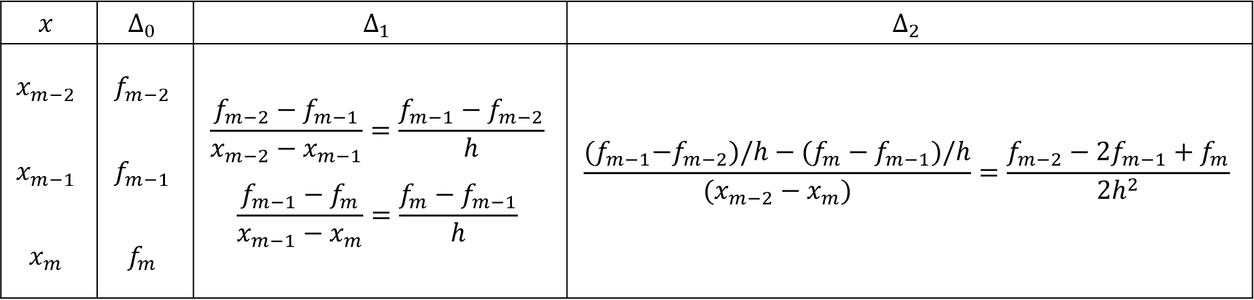

*Таблица разделённых разностей к решению задачи 3*

Производную в правой граничной точке будем находить по правилу, упоминавшемуся в решении предыдущей задачи. Для этого нам нужен полином "назад". Выписываем его по последней косой строке таблицы:

$$P_2(x)=f_m+\frac{f_m-f_{m-1}}{h}(x-x_m)+\frac{f_{m-2}-2f_{m-1}+f_m}{2h^2}(x-x_m)(x-x_{m-1}).$$

Пользуемся правилом: зачёркиваем свободный член и скобку $(x-x_m)$. В получившийся полином вместо $x$ подставляем $x_m$:

$$P_2'(x)=\frac{f_m-f_{m-1}}{h}+\frac{f_{m-2}-2f_{m-1}+f_m}{2h^2}(x_m-x_{m-1})=\frac{f_{m-2}-4f_{m-1}+3f_m}{2h}\equiv f'_m.$$

Как видим, получилась та же формула численного дифференцирования.

# Решение нелинейных уравнений с помощью обратной интерполяции

Приближение функций интерполяционными полиномами можно использовать для решения нелинейных уравнений. Соответствующий метод обычно называется **методом обратной интерполяции**. Его суть заключается в следующем.

Пусть требуется решить нелинейное уравнение вида $g(x)=0$. Будем считать, что искомый корень $x=\xi$ локализован на отрезке $[a,b]$, причём функция $g=g(x)$ непрерывна и **строго монотонна** на этом отрезке. Дополнительно предположим, что образ отрезка $U=\big\{f(x)\in\mathbb{R}:\phantom{,}x\in[a,b]\big\}$ является числовым промежутком (отрезком, интервалом, полуинтервалом). Тогда, согласно теореме об обратной функции, на числовом промежутке $U$ определена функция $g^{-1}\equiv f:\phantom{,}U\to [a,b]$, которая, как и исходная функция $g$, строго монотонна и непрерывна. Очевидно, из равенства $g(\xi)=0$ следует, что $f(0)=\xi$.

Разумеется, если есть возможность **аналитически** обратить функцию $g$, то для решения нелинейного уравнения не нужно никакой интерполяции: достаточно вычислить значение найденной обратной функции в нуле. Однако на практике обратить нелинейную функцию почти никогда не удаётся. Поэтому можно поступить так:

* ввести на отрезке локализации $[a,b]$ сетку и построить сеточную проекцию $\mathscr{G}_g$ функции $g$,
* обратить сеточную функцию $\mathscr{G}_g$ (т.е. просто поменять местами числа в каждой паре "аргумент-значение", входящей в функцию $\mathscr{G}_g$) — в результате получится (обратная) сеточная функция $\mathscr{F}_f$,
* построить для функции $\mathscr{F}_f$ интерполяционный полином $P_n$ и найти (приближённо) искомый корень как величину $P_n(0)$.

В отличие от итерационных методов численного решения нелинейных уравнений, **предложенный алгоритм не является итерационным**. Этим объясняется его главный недостаток: **прямой контроль точности приближения к корню здесь невозможен**. Ошибку интерполяции можно оценить теоретически (это будет сделано в следующем разделе), но в оценку войдёт максимум $(n+1)$-й производной приближаемой функции, поэтому на практике эта оценка почти бесполезна.

Отметим, что существуют методы численного решения нелинейных уравнений, включающие обратную интерполяцию в качестве составной части более сложного алгоритма. Например, метод Брента на каждой итерации использует обратную квадратичную интерполяцию, сочетая её с построением хорд и дихотомией. Другие методы решения нелинейных уравнений (и их систем) мы будем изучать на семинаре 10.


## Задача 4

Найти **положительный** корень уравнения $\sin x + x^2-1=0$ методом обратной интерполяции.

**Решение.** Положительный корень уравнения локализован на отрезке $[0,1]$, а (непрерывная) функция $g(x)=\sin x + x^2-1$ строго возрастает при всех $x\geq 0$. Таким образом, существует строго монотонная (более конкретно — тоже строго возрастающая) обратная функция $f=g^{-1}$, поэтому применение метода обратной интерполяции оправданно.

Запрограммируем функцию ```create_inv_table```, проецирующую исходную функцию $g$ на сетку с заданным числом узлов $k=n+1$ и возвращающую таблицу значений **уже обращённой** сеточной функции (т.е. функции $\mathscr{F}_f$). Для определённости полагаем, что граничные узлы сетки совпадают с граничными точками отрезка локализации корня (мы включаем границы отрезка в сигнатуру функции ```create_inv_table``` в виде кортежа).

In [43]:
import numpy as np

def create_inv_table(g, bracket: tuple, k: int):
    x = np.linspace(bracket[0], bracket[1], k) # равномерная сетка из k узлов
    y = np.vectorize(g)(x)

    return y, x

Остаётся применить написанную выше (при решении задачи 2) функцию ```Newton_poly_forward```:

In [44]:
def solve_inverse_interp(g, bracket: tuple, n: int):
    x, y = create_inv_table(g, (0, 1), n)

    return float(Newton_poly_forward(x, y, 0))

Посмотрим, как меняется получаемое приближение к корню в зависимости от количества узлов сетки $n+1$:

In [45]:
from ipywidgets import interact, IntSlider

n_w = IntSlider(min=1, max=50, step=1, value=4)

def test_solver(n: int):
    g = lambda x: np.sin(x) + x**2 - 1
    x = solve_inverse_interp(g, (0, 1), n)
    print('Приближение к корню:', x)

interact(test_solver, n=n_w);

interactive(children=(IntSlider(value=4, description='n', max=50, min=1), Output()), _dom_classes=('widget-int…

Найденное приближение к корню можно сравнить с приближением, полученным, например, встроенной функцией ```brentq``` библиотеки ```scipy```:

In [46]:
from scipy.optimize import brentq

g = lambda x: np.sin(x) + x**2 - 1

brentq(g, 0, 1, xtol=1e-16)

0.6367326508052821

Как видим, метод обратной интерполяции показал неплохой результат: при $n=50$ он дал 13 верных знаков корня. Правда, расчёт проводится сравнительно долго (по вполне понятной причине — из-за присутствия в функции ```Newton_poly_forward``` циклов):

In [47]:
%time brentq(g, 0, 1, xtol=1e-16)

CPU times: user 109 µs, sys: 6 µs, total: 115 µs
Wall time: 122 µs


0.6367326508052821

In [48]:
%time solve_inverse_interp(g, (0, 1), 50)

CPU times: user 2.22 ms, sys: 0 ns, total: 2.22 ms
Wall time: 2.3 ms


0.6367326508052429

**Упражнение 9.** В демонстрации, приведённой после задачи 2, мы видели, что при больших $n$ функция ```Newton_poly_forward``` выдаёт некорректный результат. Однако в последних примерах нам удалось запустить её при $n=50$ без видимых проблем. Как разрешается это противоречие?

# Погрешность интерполяции

Выше мы сформулировали задачу интерполяции и рассмотрели один из наиболее простых и распространённых способов интерполирования таблично заданных функций — **алгебраическую интерполяцию**. Мы познакомились с двумя формами записи интерполяционного полинома: Лагранжа и Ньютона, — но пока не затрагивали вопроса о погрешностях, возникающих при приближении функции-оригинала этими полиномами. Этому вопросу посвящён настоящий раздел.

Как и ранее, будем считать, что на конечном отрезке $[a,b]\subset R$ введена сетка из $n+1$ узлов и определена функция-оригинал $f$ (напомним, что на практике она обычно неизвестна). Эту функцию мы приближаем интерполянтом $\widetilde{f}\equiv P_n$, имеющим вид алгебраического полинома (в форме Лагранжа или Ньютона). Дополнительно предполагаем, что функция-оригинал $n+1$ раз непрерывно дифференцируема. Назначение последнего требования станет ясно из дальнейшего.

Поскольку и $f$, и $P_n$ — скалярные функции скалярного аргумента, в качестве меры погрешности интерполяции в точке можно выбрать модуль разности значений функций $f$ и $P_n$, вычисленных в заданной точке $x\in[a,b]$. Иначе говоря, о величине ошибки интерполяции в точке можно судить по величине модуля разности

$$f(x)-P_n(x)\equiv R_n(x).$$

Функция $R_n(x)$ называется **остаточным членом интерполяции**. В силу постановки задачи интерполяции очевидно, что в узлах заданной сетки остаточный член интерполяции равен нулю: $R_n(x_i)=0$, $0\leq i\leq n$. Другими словами, в арифметике бесконечной разрядности **погрешность интерполяции в узлах сетки нулевая**.

Нас интересует оценка на модуль остаточного члена интерполяции в некоторой точке $\widehat{x}\in[a,b]$, **не совпадающей ни с одним из узлов сетки**, введённой на отрезке $[a,b]$: $\widehat{x}\neq x_i$, $0\leq i\leq n$. Чтобы получить такую оценку, рассмотрим вспомогательную функцию

$$g(x, A)=R_n(x)-A\cdot\omega_n(x).$$

Через $A$ здесь обозначена некоторая константа; кроме того, использована введённая выше функция

$$\omega_n(x)=\prod\limits_{i=0}^n(x-x_i).$$

Легко видеть, что **при произвольной константе** $A$ функция $g(x,A)$ равна нулю в узлах сетки: $g(x_i,A)=0$, $0\leq i\leq n$. Действительно, как уже отмечалось выше, $R_n(x_i)=0$, а из определения функции $\omega_n(x)$ следует, что и $\omega_n(x_i)=0$. Таким образом, **при произвольной константе** $A$ функция $g(x,A)$ имеет $n+1$ нулей (точнее — **не менее** $n+1$ нулей) на отрезке $[a,b]$.

Подберём константу $A$ так, чтобы функция $g(x,A)$ гарантированно имела ещё один нуль, причём именно в точке $x=\widehat{x}$. Очевидно, для этого достаточно положить

$$A=\widehat{A}\equiv\frac{R_n(\widehat{x})}{\omega_n(\widehat{x})}=\frac{f(\widehat{x})-P_n(\widehat{x})}{\omega_n(\widehat{x})}.$$

Подчеркнём, что выбор такого значения для константы $A$ корректен, поскольку точка $\widehat{x}$ не совпадает ни с одним из узлов сетки, так что $\omega_n(\widehat{x})\neq 0$. Итак, функция $g=g(x,\widehat{A})$ имеет не менее $n+2$ нулей на отрезке $[a,b]$: $n+1$ нулей в точках, совпадающих с узлами сетки, и по крайней мере ещё один нуль в точке $x=\widehat{x}$.

Выше мы предположили, что $f\in C^{n+1}[a,b]$. Тогда, очевидно, и $g(x,\widehat{A})\in C^{n+1}[a,b]$, поскольку функции $P_n$ и $\omega_n$, входящие в определение функции $g$, суть полиномы. Так как $g(x,\widehat{A})\in C^{n+1}[a,b]$, можно $n+1$ раз применить теорему Ролля. Из неё следует, что если функция $g(x,\widehat{A})$ имеет не менее $n+2$ нулей на отрезке $[a,b]$, то первая производная $g'(x,\widehat{A})\in C^{n}[a,b]$ имеет не менее $n+1$ нулей на том же отрезке, вторая производная $g''(x,\widehat{A})\in C^{n-1}[a,b]$ — не менее $n$ нулей и т.д. до $(n+1)$-й производной $g^{(n+1)}(x,\widehat{A})\in C^{0}[a,b]$, имеющей не менее одного нуля на отрезке $[a,b]$. Значит, существует точка $\xi\in[a,b]$ такая, что $g^{(n+1)}(\xi,\widehat{A})=0$, т.е.

$$R^{(n+1)}_n(\xi)-\widehat{A}\cdot\omega_n^{(n+1)}(\xi)=f^{(n+1)}(\xi)-\widehat{A}\cdot (n+1)!=0.$$

Мы учли, что $P_n^{(n+1)}(x)=0$ в силу того, что $P_n$ — полином степени не выше $n$; кроме того легко показать, что $\omega_n^{(n+1)}(\xi)=(n+1)!$.

**Упражнение 10.** Исходя из определения функции $\omega_n=\omega_n(x)$, докажите, что $\omega_n^{(n+1)}(x)=(n+1)!$.

*Указание.* Примените индукцию по $n$.

Из последнего равенства следует, что

$$\widehat{A}=\frac{f^{(n+1)}(\xi)}{(n+1)!}.$$

Подставляя сюда найденное выше значение для $\widehat{A}$, получаем:

$$f(\widehat{x})-P_n(\widehat{x})=\frac{f^{(n+1)}(\xi)}{(n+1)!}\cdot\omega_n(\widehat{x}).$$

Иначе говоря,

$$|R_n(\widehat{x})|=\frac{\big|f^{(n+1)}(\xi)\big|}{(n+1)!}\cdot|\omega_n(\widehat{x})|,\quad\xi\in[a,b].$$

Мы вывели эту формулу для точки $\widehat{x}\in [a,b]$, не совпадающей ни с одним из узлов сетки. Однако $R_n(x_i)=\omega_n(x_i)=0$, $0\leq i\leq n$, и поэтому та же формула справедлива и для узлов сетки. Значит, в ней можно заменить $\widehat{x}$ на $x$, считая, что $x$ — произвольная точка, принадлежащая отрезку $[a,b]$. Следует также заметить, что точка $\xi$ в нашем выводе определяется для конкретного $\widehat{x}$, так что разным $\widehat{x}$ отвечают, вообще говоря, разные $\xi$.

Итак, для любого $x\in [a,b]$ можно указать точку $\xi\in[a,b]$ такую, что

$$\big|R_n(x)\big|=\frac{\big|f^{(n+1)}(\xi)\big|}{(n+1)!}\cdot\big|\omega_n(x)\big|.$$

Если взять точную верхнюю грань по $\xi$ от обеих частей равенства, то получится искомая оценка на погрешность интерполяции, справедливая для фиксированной точки $x\in[a,b]$:

$$\big|R_n(x)\big|\leq \delta_\text{int}^{(\text{m})}(x)\equiv\frac{M_{n+1}}{(n+1)!}\cdot\big|\omega_n(x)\big|,\quad M_{n+1}=\sup_{\xi\in[a,b]}\big|f^{(n+1)}(\xi)\big|.$$

Можно оценить погрешность не в заданной точке $x\in [a,b]$, а на всём отрезке $[a,b]$ — для этого следует взять точную верхнюю грань и по $x$:

$$\delta_\text{int}^{(\text{m})}(x)\leq\Delta^{(\text{m})}_\text{int}\equiv\sup_{x\in[a,b]}\delta^{(\text{m})}_\text{int}(x)=\frac{M_{n+1}\cdot\Vert\omega_n(x)\Vert_C}{(n+1)!},\quad \Vert\omega_n(x)\Vert_C=\sup_{x\in[a,b]}\big|\omega_n(x)\big|.$$

Если рассматриваемая сетка является равномерной, а её граничные узлы совпадают с граничными точками отрезка $[a,b]$, то

$$x_i=a+i\cdot h,\quad h=\frac{b-a}{n},\quad 0\leq i\leq n.$$

Предполагая, что произвольная точка $x\in [a,b]$ лежит между $l$-м и $(l+1)$-м узлами (или совпадает с $l$-м узлом), можем написать:

$$\big|\omega_n(x)\big|=\prod\limits_{i=0}^n\big|x_l+q\cdot h-x_i\big|=\frac{(b-a)^{n+1}}{n^{n+1}}\prod\limits_{i=0}^n\big|l-i+q\big|,\quad q\in [0,1),\quad 0\leq l\leq n.$$

Нетрудно показать, что

$$\prod\limits_{i=0}^n\big|l-i+q\big|\leq n!,$$

поэтому

$$\big|\omega_n(x)\big|\leq\frac{(b-a)^{n+1}\cdot n!}{n^{n+1}}.$$

Окончательно имеем следующую оценку погрешности интерполяции для случая равномерной сетки:

$$\big|R_n(x)\big|\leq\frac{M_{n+1}(b-a)^{n+1}}{(n+1)\,n^{n+1}}.$$

Она завышена тем сильнее, чем больше $n$.

Отметим, что все полученные формулы имеют, в основном, теоретическое значение: на практике применить их обычно не удаётся, так как неизвестна функция-образ $f$ (и, соответственно, неизвестна константа $M_{n+1}$).

## Задача 5


Функция $f(x)=\sin x$ приближена на отрезке $[0,\pi/3]$ алгебраическим полиномом, построенным по нижеследующей таблице. Оценить ошибку интерполяции.

$$
\begin{array}{c|cccc}
  x_i & 0 & \pi/6 & \pi/4 & \pi/3 \\
  \hline
  y_i=\sin{x_i} & 0,0000 & 0,5000 & 0,7071 & 0,8660
\end{array}
$$

**Решение** заключается в вычислении (или оценке сверху) величин $M_4$ и $\Vert\omega_n(x)\Vert_C$, а также применении выведенной выше формулы (в данном случае $n=3$, поскольку значения функции заданы в четырёх узлах, а узлы нумеруются, начиная с нуля). Заметим, что $f^{(4)}(x)=\sin{x}=f(x)$, причём функция $f(x)$ строго возрастает на отрезке $[0,\pi/3]$ и принимает на нём неотрицательные значения. Поэтому

$$M_4=f\Big(\frac{\pi}{3}\Big)=\sin\frac{\pi}{3}=\frac{\sqrt{3}}{{2}}.$$

Величина $\Vert\omega_n(x)\Vert_C$ представляет собой точную верхнюю грань выражения

$$\big|\omega_3(x)\big|=\big|(x-0)(x-\pi/6)(x-\pi/4)(x-\pi/3)\big|,$$

рассматриваемого при $x\in[0,\pi/3]$. В некоторых задачах точную верхнюю грань подобного произведения скобок легко найти аналитически. В данном случае проще дать оценку сверху на $\Vert\omega_n(x)\Vert_C$. Её можно установить, например, с помощью графика функции $\omega_3=\omega_3(x)$. Напишем программу для его построения:


In [49]:
import numpy as np
import matplotlib.pyplot as plt

def graph(bracket: tuple):
    func = lambda x: x * (x - np.pi/6) * (x - np.pi/4) * (x - np.pi/3)
    func = np.vectorize(func)

    x = np.arange(bracket[0], bracket[1] + 0.001, 0.001)
    y = func(x)

    fig, ax = plt.subplots()
    ax.plot(x, y, color='blue')

    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")

    plt.title("График функции $y=\\omega_3(x)$")

    plt.show()

Сначала построим график функции на всём отрезке $[0,\pi/3]$:

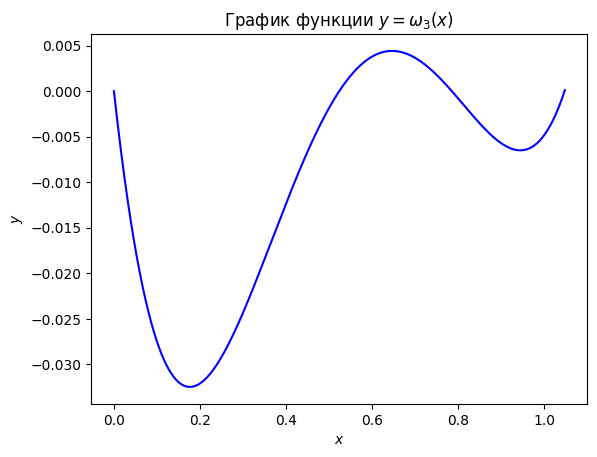

In [50]:
graph((0, np.pi/3))

Видно, что наибольшее по модулю значение расположено в окрестности точки $x=0,2$. "Присмотримся" к этой окрестности:

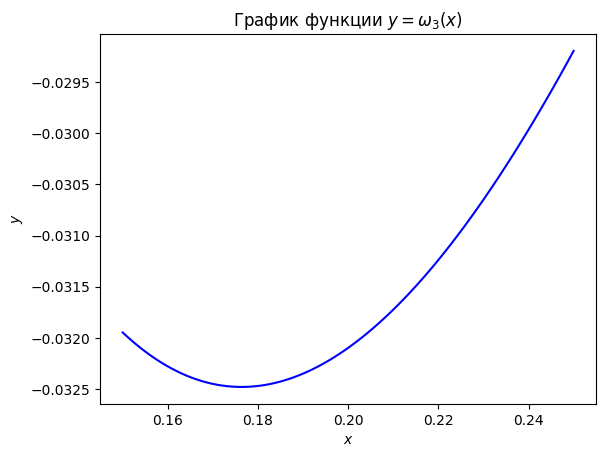

In [51]:
eps = 0.05
graph((0.2 - eps, 0.2 + eps))

Как видим, можно считать, что $|\omega_3(x)|\leq 0,033$. Тогда искомая оценка:

$$\Delta^{(\text{m})}_\text{int}\leq\frac{1}{4!}\cdot\frac{\sqrt{3}}{2}\cdot 0,033=1,191\cdot 10^{-3}.$$

Заметим, что предложенная в условии задачи сетка не является равномерной. Однако при добавлении узла $x=\pi/12$ она становится равномерной (с шагом $h=\pi/12$). Оценим ошибку интерполяции и в этом случае, т.е. решим ту же задачу для следующей таблицы:

$$
\begin{array}{c|ccccc}
  x_i & 0 & \pi/12 & \pi/6 & \pi/4 & \pi/3 \\
  \hline
  y_i=\sin{x_i} & 0,0000 & 0,2588 & 0,5000 & 0,7071 & 0,8660
\end{array}
$$

Имеем: $n=4$, $f^{(5)}=\cos{x}$. Очевидно, что $M_5=1$. В силу равномерности сетки удобно воспользоваться формулой, выведенной в конце предыдущего раздела:

$$|R_4(x)|\leq\frac{1\cdot (\pi/3)^5}{5\cdot 4^5}=2,460\cdot 10^{-4}.$$

# Пример Рунге

Вернёмся к оценке

$$\big|R_n(x)\big|\leq \delta^{(\text{m})}_\text{int}(x)\equiv\frac{M_{n+1}}{(n+1)!}\cdot\big|\omega_n(x)\big|,$$

из которой выше мы получили две другие оценки на погрешность интерполяции. Из этой формулы следует, что если функция-образ $f$ и отрезок $[a,b]$ зафиксированы (как это часто бывает на практике), то **погрешность интерполяции может изменяться в силу двух причин**. Во-первых, при заданном $n$ узлы сетки могут располагаться на отрезке по-разному, а от их расположения зависит величина $\big|\omega_n(x)\big|$. Во-вторых, число $n$ (и, соответственно, количество узлов сетки $n+1$) тоже может быть различным; его изменение влияет и на константу $M_{n+1}/(n+1)!$, и на величину $\big|\omega_n(x)\big|$. Возникает естественный вопрос: как можно уменьшить оценку на погрешность интерполяции, пользуясь двумя указанными способами её изменения — за счёт выбора **количества** узлов и **самих узлов**? Разумеется, этот вопрос имеет смысл только в том случае, если при интерполировании неизвестной функции есть возможность распоряжаться выбором сетки (т.е. доступны значения функции $f$ в произвольных узлах).

На первый взгляд может показаться, что для уменьшения оценки на погрешность достаточно увеличивать $n$, т.е. включать в сетку много узлов, не особенно заботясь об их расположении на отрезке $[a,b]$. С одной стороны, это кажется естественным в силу того, что приведённая формула содержит деление на $(n+1)!$, а факториал возрастает, как известно, очень быстро. С другой стороны, из общих соображений представляется очевидным, что чем больше узлов содержит сетка, тем больше информации о неизвестной функции используется при построении интерполянта, а следовательно, и результат построения должен лучше соответствовать функции-оригиналу. Все эти выводы согласуются с примером из предыдущей задачи: мы видели, что добавление в сетку одного узла привело к уменьшению оценки погрешности почти на порядок.

Оказывается, однако, что **в действительности погрешность интерполяции может и не убывать с ростом числа узлов в сетке**, т.е. для уменьшения погрешности, вообще говоря, недостаточно просто увеличить параметр $n$. Классическим контрпримером, иллюстрирующим это утверждение, является так называемый **пример Рунге** (предложен немецким математиком Карлом Рунге в 1901 г.). В этом примере в качестве функции-оригинала рассматривается функция

$$f_\text{R}(x)=\frac{1}{1+25x^2}$$

на отрезке $[-1,1]$. Введём на этом отрезке равномерную сетку, состоящую из $n+1$ узлов:

$$x_i=-1+i\cdot\frac{2}{n},\quad 0\leq i\leq n.$$

Можно показать, что погрешность интерполяции функции $f_\text{R}$ алгебраическим полиномом $P_n$ по значениям $f_\text{R}(x_i)$ в узлах введённой сетки стремится к бесконечности при увеличении $n$:

$$\Vert f_\text{R}(x)-P_n(x)\Vert_C=\sup\limits_{x\in[-1,1]}\big|f_\text{R}(x)-P_n(x)\big|\to\infty,\quad n\to\infty.$$

Мы не будем приводить строгого аналитического анализа этого примера и ограничимся численной демонстрацией. Напишем программу, составляющую таблицу значений функции $f_\text{R}$ на отрезке $[-1,1]$ по заданному количеству узлов $n+1$ равномерной сетки:

In [52]:
import numpy as np

def Runge_function(x: float):
    return 1 / (1 + 25 * x**2)

def create_table(n: int):
    x = np.linspace(-1, 1, n+1)
    y = np.vectorize(Runge_function)(x)

    return x, y

При различных $n$ будем строить алгебраические интерполянты по найденной таблице значений функции $f_\text{R}$. Это можно сделать с помощью уже упоминавшегося на первом семинаре класса ```BarycentricInterpolator``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.BarycentricInterpolator.html)) модуля ```interpolate``` ([документация](https://docs.scipy.org/doc/scipy/reference/interpolate.html#module-scipy.interpolate)) библиотеки ```scipy```. Построенные полиномы $P_n$ будем отображать на графике вместе с самой функцией Рунге $f_\text{R}$ и точками, соответствующими узлам сетки. Кроме того, добавим в программу вычисление погрешности интерполяции:

In [53]:
from scipy.interpolate import BarycentricInterpolator
import matplotlib.pyplot as plt

def graph_Runge(n: int):
    x_points, y_points = create_table(n)
    p_n = BarycentricInterpolator(x_points, y_points)

    grid = np.linspace(-1, 1, 1000)
    y_Runge = np.vectorize(Runge_function)(grid)
    y_p = p_n(grid)

    fig, ax = plt.subplots()
    ax.plot(grid, y_Runge, color='red')
    ax.plot(grid, y_p, color='blue')
    ax.scatter(x_points, y_points, color='blue', s=15)

    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")

    ax.set_xticks([-1, 0, 1])
    ax.set_xlim([-1.1, 1.1])
    ax.set_ylim([-0.6, 1.6])

    plt.title("Пример Рунге")

    Delta = np.max( np.abs(y_Runge - y_p) )
    print("Погрешность интерполяции: {:.3e}".format(Delta))

    plt.show()

In [54]:
from ipywidgets import interact, IntSlider

n_w = IntSlider(min=1, max=50, step=1, value=3)

interact(graph_Runge, n=n_w);

interactive(children=(IntSlider(value=3, description='n', max=50, min=1), Output()), _dom_classes=('widget-int…

Заметим, что в предложенной программе погрешность интерполяции вычисляется приближённо: сначала находится разность массивов, содержащих значения функции-оригинала и функции-образа (интерполянта), а затем определяется наибольший по модулю элемент полученного массива-разности. Следует иметь в виду, что такая оценка может оказаться заниженной. Однако в данном случае это не мешает проследить интересующую нас закономерность.

Видно, что с увеличением $n$ последовательность полиномов $P_n$ сходится к функции Рунге в средней части отрезка $[-1,1]$ (примерно при $|x|<0,6$), а по краям отрезка сходимость отсутствует и наблюдаются сильные осцилляции, приводящие к резкому росту погрешности.

Оказывается, что **проиллюстрированный** выше **эффект является весьма общим**: для любой последовательности сеток $G_n$, заданных на отрезке $[a,b]$, можно указать непрерывную функцию $f$ такую, что построенные по таблицам её значений алгебраические полиномы $P_n$ не будут сходиться к ней равномерно с увеличением $n$ (**теорема Фабера—Бернштейна**). Иными словами, **пример "плохой" функции, на которой "ломается" алгебраическая интерполяция, можно подобрать для любой сетки**.

С другой стороны, известно, что для всякой функции $f$, непрерывной на отрезке $[a,b]$, найдётся последовательность сеток $G_n$, дающая **равномерно сходящийся интерполяционный процесс**, т.е. обеспечивающая равномерную сходимость полиномов $P_n$, построенных по значениям $f(x_i)$ в узлах сеток $G_n$, к функции $f$ (**теорема Марцинкевича**). Проще говоря, **для любой непрерывной функции можно найти "хорошую" сетку и построить на этой сетке алгебраический полином со сколь угодно маленькой погрешностью**. Однако отыскать такую "хорошую" сетку для заданной функции чрезвычайно трудно, а на практике это и вовсе невозможно сделать, потому что неизвестна функция-оригинал. Впрочем, существует приём (мы познакомимся с ним в следующем разделе), позволяющий **гарантированно минимизировать** погрешность интерполяции (нужно только понимать, что минимизация погрешности, конечно, не равносильна равномерной сходимости). Но приём, о котором идёт речь, связан со специальным выбором узлов сетки, а выбор узлов доступен не всегда. Именно поэтому **в реальных вычислениях глобальная интерполяция алгебраическими полиномами применяется не так часто**: даже при не очень большом числе узлов сетки есть опасность столкнуться с ростом погрешности интерполяции (особенно если приходится работать с фиксированными узлами, т.е. если узлы нельзя выбирать). Этот недостаток глобальной интерполяции объясняет широкое распространение **сплайн-интерполяции**, о которой мы будем говорить на следующем семинаре.

# Интерполяция на чебышёвской сетке

Итак, при приближении функций алгебраическими полиномами высоких степеней погрешность метода может быть очень значительной по величине. Один из способов решения этой проблемы заключается в **специальном выборе узлов сетки**, позволяющем минимизировать погрешность интерполяции. Суть этого приёма заключается в следующем.

Мы видели, что в формулу для величины $\Delta^{(\text{m})}_\text{int}$, являющейся оценкой на погрешность интерполяции на всём отрезке $[a,b]$, входит в качестве сомножителя $C$-норма полинома $\omega_n$ (степени $n+1$). Поставим задачу минимизировать эту норму **при фиксированном** $n$. Заметим, что нули полинома $\omega_n$ совпадают с узлами сетки, а коэффициент при его старшем члене равен единице. Таким образом, выбрав среди всех полиномов степени $n+1$ (с единичным коэффициентом при старшем члене) тот, который имеет наименьшую $C$-норму, мы автоматически найдём сетку, доставляющую минимум оценке погрешности $\Delta^{(\text{m})}_\text{int}$ — в качестве узлов такой сетки достаточно будет взять нули выбранного полинома. Поскольку $\Vert\omega_n(x)\Vert_C=\Vert\omega_n(x)-0\Vert_C$, можно утверждать, что **задача минимизации погрешности алгебраической интерполяции на сетке из $n+1$ узлов сводится к подбору полинома степени $n+1$, имеющего единичный коэффициент при старшем члене и наименьшее уклонение от нуля** (в смысле $C$-нормы).

Оказывается, решением этой задачи служит **алгебраический полином, пропорциональный многочлену Чебышёва** (первого рода) **степени** $n+1$. О многочленах Чебышёва мы уже упоминали на пятом семинаре. Напомним, что так называются многочлены

$$T_k(x)=\cos(k\arccos{x}),\quad k=0,\,1,\,\dots$$

степени $k$, определённые на отрезке $[-1,1]$. Можно показать, что для них справедливо рекуррентное соотношение

$$T_{k+1}(x)=2xT_k(x)-T_{k-1}(x),\quad T_0(x)=1,\quad T_1(x)=x.$$

Таблицу из нескольких первых многочленов Чебышёва можно получить с помощью функции ```chebyshevt_poly``` ([документация](https://docs.sympy.org/latest/modules/polys/reference.html#sympy.polys.orthopolys.chebyshevt_poly)) библиотеки ```sympy```:

In [55]:
from sympy import latex, chebyshevt_poly
from IPython.display import display, Math

def Chebyshev_print(p: int):
    print('Несколько первых многочленов Чебышёва:')
    for i in range(p):
        display( Math( 'T_{' + str(i) + '}=' + latex(chebyshevt_poly(i) ) ) )

Chebyshev_print(11)

Несколько первых многочленов Чебышёва:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (2 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Графики первых пяти многочленов Чебышёва мы уже строили на пятом семинаре. Для наглядности повторим эту демонстрацию:

In [56]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

def graph_Chebyshev_polynomials(k: int):
    grid = np.arange(-1, 1 + 0.01, 0.01)

    fig, ax = plt.subplots()

    for i in range(k):
        y = sp.special.eval_chebyt(i, grid)
        ax.plot(grid, y, label=i)

        ax.set_xlabel("$x$")
        ax.set_ylabel("$y$")

    ax.legend(title="Степень $k$", loc="upper left", bbox_to_anchor=(1, 1))

    plt.title("Графики многочленов Чебышёва $y=T_k(x)$")

    plt.show()

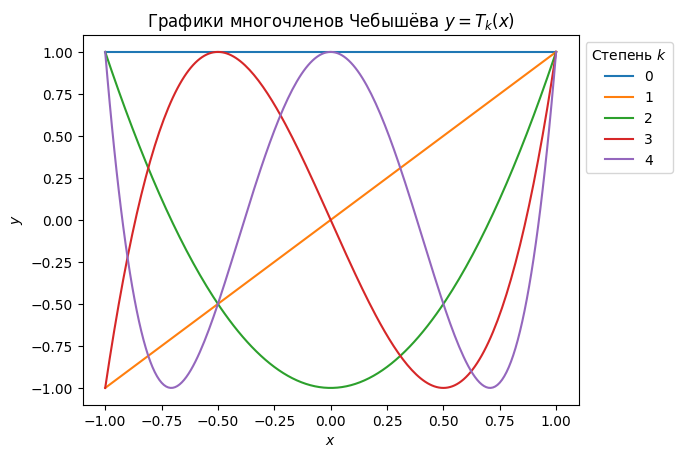

In [57]:
graph_Chebyshev_polynomials(5)

Многочлены Чебышёва обладают многими свойствами, важными с точки зрения практики. Приведём сводку некоторых из них:

1. многочлены чётных степеней $T_{2k}(x)$ содержат только чётные степени $x$ (и поэтому являются чётными функциями), а многочлены нечётных степеней $T_{2k+1}(x)$ — только нечётные степени $x$ (и поэтому являются нечётными функциями);

2. сумма коэффициентов любого многочлена $T_k(x)$ равна единице;

3. старший коэффициент многочлена $T_k(x)$ есть $2^{k-1}$;

4. справедливы следующие соотношения:

   $$T_k(1)=1,\quad T_k(-1)=(-1)^k,\quad T_{2k}(0)=(-1)^k,\quad T_{2k+1}(0)=0,$$

   $$T_k'(1)=k^2,\quad T_k'(-1)=(-1)^k \cdot k^2,\quad T_{2k}'(0)=(-1)^k,\quad T_{2k+1}'(0)=(2k+1)\cdot\sin\bigg[\frac{2k+1}{2}\pi\bigg];$$

5. верны следующие оценки:
  
   $$\big|T_k(x)\big|\leq 1,\quad \big|T'_k(x)\big|\leq k^2,\quad x\in[-1,1],$$

6. многочлены Чебышёва ортогональны с весом:
  
   $$\int\limits_{-1}^{1}\frac{dx}{\sqrt{1-x^2}}\,T_k(x)T_l(x)=
  \begin{cases}
    0,&\quad k\neq l,\\
    \pi/2,&\quad k=l>0,\\
    \pi,&\quad k=l=0;
  \end{cases}$$

7. при $|x|>1$ справедлива формула
   
   $$T_k(x)=\frac{\big(x+\sqrt{x^2-1}\big)^k+\big(x-\sqrt{x^2-1}\big)^k}{2};$$

8. все $k$ нулей многочлена $T_k(x)$ действительны, различны, расположены на отрезке $[-1, 1]$ и задаются формулой

   $$\xi_j=\cos\bigg[\frac{2j+1}{2k}\pi\bigg],\quad j=0,\,1\,\dots,\,k-1;$$

9. между любыми двумя соседними нулями многочлена $T_k(x)$ ($k\geq 2$) расположен один и только один нуль многочлена $T_{k-1}(x)$;

10. многочлен $T_k(x)$ ($k\geq 1$) имеет $k+1$ экстремальных точек **на отрезке** $[-1,1]$, причём все они действительны, различны и задаются формулой
    
    $$\zeta_j=\cos\frac{\pi j}{k},\quad j=0,\phantom{,}1,\phantom{,}\dots,\phantom{,}k,\quad \text{так что}\quad T_k(\zeta_j)=(-1)^j;$$

    подчеркнём, что речь идёт именно об экстремумах **на отрезке** $[-1,1]$, поэтому граничные точки отрезка входят в число экстремумов в силу свойств 4 и 5; если функция $T_n(x)$ рассматривается **на всей числовой прямой**, то точки $\zeta_0=1$ и $\zeta_k=-1$ перестают быть экстремумами;

11. производная $T'_k(x)$ ($k\geq 1$) имеет $k-1$ нулей, совпадающих с экстремальными точками $\zeta_1,\,\zeta_2,\,\dots,\,\zeta_{k-1}$, поэтому за пределами отрезка $[-1,1]$ любой многочлен $T_k(x)$ монотонен;

12. если $P_k(x)$ — многочлен степени $k$ такой, что $\big|P_k(x)\big|\leq 1$ при $x\in[-1,1]$, то $\big|T_k(y)\big|\geq\big|P_k(y)\big|$ при $|y|>1$.

Вернёмся к задаче интерполяции, в рамках которой, как мы видели, нас интересует алгебраический полином **с единичным старшим коэффициентом**, наименее уклоняющийся от нуля. Оказывается, что **на отрезке** $[-1,1]$ такой полином можно получить из многочлена Чебышёва — нужно только привести его старший коэффициент к единице. Последнее делается элементарно делением на $2^{k-1}$ (в силу третьего свойства многочленов Чебышёва из приведённого выше списка). Иначе говоря, справедлива следующая теорема.

**Теорема 2 (о полиноме наименьшего равномерного уклонения от нуля)**. Если $P_k(x)$ — алгебраический полином степени $k>0$ *с единичным старшим коэффициентом*, то

$$\sup\limits_{x[-1,1]}\big|P_k(x)\big|\geq \sup\limits_{x[-1,1]}\big|\overline{T}_k(x)\big|=2^{1-k},$$

где $\overline T_k(x)$ — *приведённый многочлен Чебышёва* (т.е. многочлен Чебышёва с единичным старшим коэффициентом):

$$\overline T_k(x)=\frac{T_k(x)}{2^{k-1}}=\frac{\cos(k\arccos{x})}{2^{k-1}},\quad x\in[-1,1].$$

Принимая во внимание эту теорему и рассуждения, проведённые в начале раздела, приходим к следующему выводу. Для минимизации погрешности интерполяции **на отрезке** $[-1,1]$ достаточно выбрать в качестве узлов сетки (числом $n+1$) нули многочлена Чебышёва $T_{n+1}(x)$. Тогда полином $\omega_n(x)$ совпадёт с приведённым многочленом Чебышёва $\overline T_{n+1}(x)$, а он имеет наименьшую возможную $C$-норму (среди всех многочленов $\omega_n(x)$ **на отрезке** $[-1,1]$) в силу теоремы 2. Значит, при таком выборе узлов сетки достигается минимум величины $\Vert\omega_n(x)\Vert_C$ в оценке погрешности $\Delta_\text{int}^{(\text{m})}$.

Обобщение на случай произвольного отрезка $[a,b]$ проводится элементарно — выполняется линейная замена переменной, переводящая этот отрезок в отрезок $[-1,1]$:

$$y=\frac{2x}{b-a}-\frac{b+a}{b-a}.$$

Легко убедиться, что если $x\in [a,b]$, то $y\in [-1,1]$. После такой замены остаётся провести алгебраическую интерполяцию на сетке из нулей многочлена Чебышёва $T_{n+1}(y)$, а затем, получив интерполянт в виде функции $P_n=P_n(y)$, вернуться к переменной $x$. Можно поступить ещё проще. Обратим зависимость $y=y(x)$:

$$x=\frac{a+b}{2}+\frac{b-a}{2}\,y.$$

Нули многочлена Чебышёва $T_{n+1}(y)$ задаются формулой (см. свойство 8 из списка выше):

$$\xi_j=\cos\bigg[\frac{2j+1}{2(n+1)}\pi\bigg],\quad j=0,\,1\,\dots,\,n.$$

Те же точки в терминах переменной $x$ выглядят так:

$$x_j=\frac{a+b}{2}+\frac{b-a}{2}\,\cos\bigg[\frac{2j+1}{2(n+1)}\pi\bigg],\quad j=0,\,1\,\dots,\,n.$$

Это и есть узлы той сетки, по которым строится интерполянт на отрезке $[a,b]$. Другими словами, выполнять замены переменных не нужно: можно сразу строить интерполянт на исходном отрезке по узлам, задаваемым последней формулой. Соответствующая сетка называется **чебышёвской сеткой**.

Нетрудно показать, что при выборе чебышёвской сетки многочлен $\omega_n(x)$ на отрезке $[a,b]$ принимает следующий вид:

$$\omega_n(x)=\frac{(b-a)^{n+1}}{2^{2n+1}}\,\cos\bigg[(n+1)\arccos\frac{2x-(b+a)}{b-a}\bigg].$$

Поэтому

$$\Vert\omega_n(x)\Vert_C=\frac{(b-a)^{n+1}}{2^{2n+1}}$$

и оценка погрешности интерполяции выглядит так:

$$\big|R_n(x)\big|\leq\Delta_\text{int}^{(\text{m})}=\frac{M_{n+1}}{(n+1)!}\frac{(b-a)^{n+1}}{2^{2n+1}}.$$

Итак, **если заданы функция-оригинал $f$ и отрезок $[a,b]$, а также зафиксирована степень алгебраического интерполянта $n$, то оценка на погрешность интерполяции на отрезке $\Delta_\text{int}^{(\text{m})}$ будет минимальной при выборе чебышёвской сетки**. Но отсюда ещё не следует, что величина $\Delta_\text{int}^{(\text{m})}$ не будет нарастать с увеличением $n$ (как в примере Рунге). Поэтому **не нужно думать, что выбор чебышёвской сетки полностью решает проблему погрешности алгебраической интерполяции**. При прочих равных условиях эта сетка является оптимальной, но даже для неё можно подобрать "плохую" функцию-оригинал (такую, что при устремлении числа узлов сетки к бесконечности погрешность интерполяции тоже будет стремиться к бесконечности).

Впрочем, на практике применение чебышёвской сетки во многих случаях улучшает сходимость последовательности интерполяционных полиномов. Повторим, например, обсуждавшуюся выше демонстрацию с функцией Рунге $f_\text{R}$, но не на равномерной сетке, а на чебышёвской:

In [58]:
import numpy as np
from scipy.interpolate import BarycentricInterpolator
from scipy.special import roots_chebyt
import matplotlib.pyplot as plt

def Runge_function(x: float):
    return 1 / (1 + 25 * x**2)

def create_table_Chebyt(n: int):
    x, _ = roots_chebyt(n+1)
    y = np.vectorize(Runge_function)(x)

    return x, y

def graph_Runge_Chebyt(n: int):
    x_points, y_points = create_table_Chebyt(n)
    p_n = BarycentricInterpolator(x_points, y_points)

    grid = np.linspace(-1, 1, 10000)
    y_Runge = np.vectorize(Runge_function)(grid)
    y_p = p_n(grid)

    fig, ax = plt.subplots()
    ax.plot(grid, y_Runge, color='red')
    ax.plot(grid, y_p, color='blue')
    ax.scatter(x_points, y_points, color='blue', s=15)

    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")

    ax.set_xticks([-1, 0, 1])
    ax.set_xlim([-1.1, 1.1])
    ax.set_ylim([-0.6, 1.6])

    plt.title("Пример Рунге с чебышёвской сеткой")

    Delta = np.max( np.abs(y_Runge - y_p) )
    print("Погрешность интерполяции: {:.3e}".format(Delta))

    plt.show()

В этой программе нули многочлена Чебышёва на отрезке $[-1,1]$, служащие узлами сетки, получены с помощью функции ```roots_chebyt``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.roots_chebyt.html)) модуля ```special``` ([документация](https://docs.scipy.org/doc/scipy/reference/special.html#module-scipy.special)) библиотеки ```scipy``` (мы уже упоминали эту функцию на пятом семинаре). Строим график:

In [59]:
from ipywidgets import interact, IntSlider

n_w = IntSlider(min=1, max=50, step=1, value=3)

interact(graph_Runge_Chebyt, n=n_w);

interactive(children=(IntSlider(value=3, description='n', max=50, min=1), Output()), _dom_classes=('widget-int…

Как видим, на этот раз осцилляций вблизи границ отрезка не обнаруживается, а погрешность интерполяции оказывается приемлемой. Можно даже попробовать взять очень большое число узлов:

Погрешность интерполяции: 2.887e-15


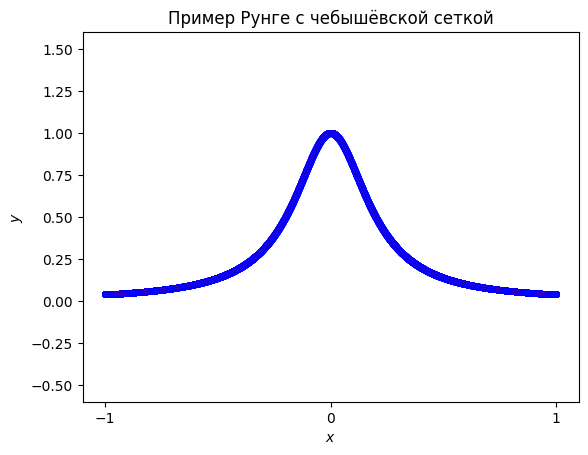

In [60]:
graph_Runge_Chebyt(10000)

## Задача 6


Построить чебышёвскую сетку из четырёх узлов на отрезке $[-2,4]$.

**Решение** заключается в использовании приведённой в предыдущем разделе формулы

$$x_j=\frac{a+b}{2}+\frac{b-a}{2}\,\cos\bigg[\frac{2j+1}{2(n+1)}\pi\bigg],\quad j=0,\,1\,\dots,\,n.$$

В данном случае $n=3$, $a=-2$, $b=4$. Имеем:

$$x_j=1+3\cdot\cos\bigg[\frac{2j+1}{8}\pi\bigg],\quad j=0,\,1,\,2,\,3.$$

Таким образом,

$$x_0=1+3\cdot\cos\frac{\pi}{8}\simeq 3,772,\quad x_1=1+3\cdot\cos\frac{3\pi}{8}\simeq 2,148,$$

$$x_2=1+3\cdot\cos\frac{5\pi}{8}\simeq -0.148,\quad x_3=1+3\cdot\cos\frac{7\pi}{8}\simeq -1,772.$$

Заметим, что узлы, получающиеся по использованной формуле, **всегда занумерованы в порядке убывания**.

Можно было бы решить задачу с помощью программы, используя уже применявшуюся выше функцию ```roots_chebyt```:

In [61]:
import numpy as np
from scipy.special import roots_chebyt

def Chebyshev_nodes(bracket: tuple, n: int):
    roots, _ = roots_chebyt(n+1)
    a, b = bracket[0], bracket[1]

    return (a + b) / 2 + (b - a) / 2 * roots

In [62]:
Chebyshev_nodes((-2, 4), n=3) # сетка содержит n+1 узлов

array([-1.7716386, -0.1480503,  2.1480503,  3.7716386])

Как видим, программа выдаёт те же узлы, но **в порядке возрастания**.

Отметим, что в библиотеке ```sympy``` имеется функция ```chebyshevt_root``` ([документация](https://docs.sympy.org/latest/modules/functions/special.html#sympy.functions.special.polynomials.chebyshevt_root)), позволяющая получать аналитические (точные) выражения для нулей полиномов Чебышёва. Функция принимает на вход два аргумента — степень полинома $n$ и порядковый номер нуля $k$, причём $0\leq k<n$ (узлы нумеруются **в порядке убывания**). Например:

In [63]:
from sympy import chebyshevt_root

chebyshevt_root(4, 0)

sqrt(sqrt(2)/4 + 1/2)

Нетрудно заметить, что это значение выражения $\cos(\pi/8)$, т.е. нуля $\xi_0$ полинома $T_4(x)$. Выше мы использовали его для приближённого подсчёта узла $x_0$ чебышёвской сетки.

## Задача 7


Построить алгебраический интерполяционный полином для функции $y=f(x)$, заданной на отрезке $[1,2]$ следующей таблицей:

$$
\begin{array}{c|ccc}
  x_i & x_0 & x_1 & x_2 \\
  \hline
  y_i & 2 & 1 & 3
\end{array}
$$

Здесь $x_i$ — узлы чебышёвской сетки.

**Решение.** Прежде всего, найдём узлы чебышёвской сетки. Применяем ту же формулу, что и в предыдущей задаче. В данном случае $n=2$, $a=1$, $b=2$. Получаем:

$$x_j=\frac{3}{2}+\frac{1}{2}\cdot\cos\bigg[\frac{2j+1}{6}\pi\bigg],\quad j=0,\,1,\,2.$$

Иначе говоря,

$$x_0=\frac{3}{2}+\frac{\sqrt{3}}{4},\quad x_1=\frac{3}{2},\quad x_1=\frac{3}{2}-\frac{\sqrt{3}}{4},$$

и таблица значений функции принимает следующий вид:

$$
\begin{array}{c|ccc}
  x_i & \quad 3/2+\sqrt{3}/4\quad & 3/2 & \quad 3/2-\sqrt{3}/4\quad \\
  \hline
  y_i & 2 & 1 & 3
\end{array}
$$

Строим таблицу разделённых разностей:

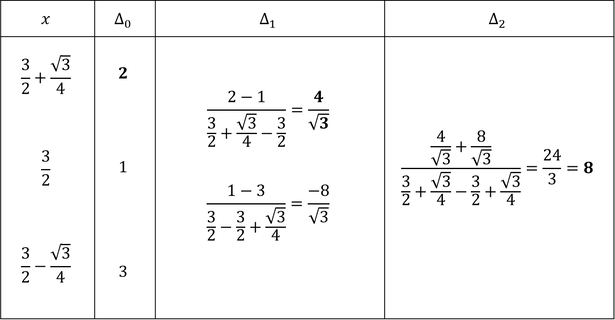

*Таблица разделённых разностей к решению задачи 7*

Остаётся выписать интерполяционный полином в форме Ньютона (используем полином "вперёд" — "собираем" его по первой косой строке таблицы):

$$P_2(x)=2+\frac{4}{\sqrt{3}}\bigg(x - \frac{3}{2} - \frac{\sqrt{3}}{4}\bigg)+8\bigg(x - \frac{3}{2} - \frac{\sqrt{3}}{4}\bigg)\bigg(x - \frac{3}{2}\bigg).$$

После преобразований:

$$P_2(x)=8x^2-\bigg(24+\frac{2\sqrt{3}}{3}\bigg)x+19+\sqrt{3}.$$

## Задача 8


Функция $f(x)=\cos(x/5)$ приближается на отрезке $[0,3]$ алгебраическим полиномом. Оценить погрешность приближения, если

* строится алгебраический интерполянт на **равномерной** сетке из четырёх узлов,
* строится алгебраический интерполянт на **чебышёвской** сетке из четырёх узлов,
* используется полином, представляющий собой отрезок ряда Маклорена, состоящий из **первых трёх ненулевых членов** этого ряда.

Сравнить полученные оценки.

**Решение.** Согласно ранее выведенным формулам, первые две оценки содержат константу $M_4$ (из условия задачи следует, что $n=3$). В данном случае

$$f^{(4)}(x)=\frac{1}{5^4}\cdot \cos\frac{x}{5}=\frac{f(x)}{5^4},$$

поэтому

$$M_4=\frac{1}{5^4}\cdot\sup\limits_{x\in[0,3]}\bigg|\cos\frac{x}{5}\bigg|=\frac{1}{5^4}.$$

В случае равномерной сетки можно воспользоваться готовой оценкой (см. выше)

$$\big|R_n(x)\big|\leq\frac{M_{n+1}(b-a)^{n+1}}{(n+1)\,n^{n+1}}.$$

Подстановка значений $n$, $a$, $b$ и $M_{n+1}$ даёт:

$$\big|R_3(x)\big|\leq\frac{3^4}{5^4\cdot 4\cdot 3^4}=\frac{1}{4\cdot 5^4}=4\cdot 10^{-4}.$$

Однако, как уже отмечалось, использованная формула даёт завышенную оценку, поэтому лучше ориентироваться на более общее неравенство

$$\big|R_n(x)\big|\leq\frac{M_{n+1}\cdot\Vert\omega_n(x)\Vert_C}{(n+1)!}.$$

Для равномерной сетки из условия задачи имеем:

$$\Vert\omega_3(x)\Vert_C=\sup_{x\in[0,3]}\big|x(x-1)(x-2)(x-3)\big|=\sup_{x\in[0,3]}\big|(x^2-3x)(x^2-3x+2)\big|.$$

Под знаком модуля мы перемножили первую и четвёртую, а также вторую и третью скобки. Легко видеть, что функция $y(x)=x^2-3x$ при $x\in[0,3]$ принимает значения из отрезка $[-9/4,0]$. В самом деле, $y'(x)=2x-3$, поэтому на отрезке $[0,3/2]$ функция $y(x)$ убывает, а на отрезке $[3/2,0]$ — возрастает. Поскольку границы отрезка $[0,3]$ совпадают с нулями функции $y(x)$, ясно, что на этом отрезке она не меняет знака, причём

$$\min\limits_{x\in[0,3]}y(x)=y(3/2)=-9/4,\quad\text{а}\quad\max\limits_{x\in[0,3]}y(x)=0.$$

Итак,

$$\Vert\omega_3(x)\Vert_C=\sup_{y\in[-9/4,\,0]}\big|y(y+2)\big|=\sup_{y\in[-9/4,\,0]}\big|y^2+2y\big|.$$

Повторяем только что проведённые рассуждения уже для функции $z(y)=y^2+2y$. На полуинтервале $[-9/4,-2)$ она принимает положительные значения, а на интервале $(-2,0)$ — отрицательные (точки $y=-2$ и $y=0$ являются её нулями). Промежутки возрастания и убывания определяются по производной $z'(y)=2y+2$: функция убывает на отрезке $[-9/4,-1]$ и возрастает на отрезке $[-1,0]$. Отсюда следует, что

$$\sup_{y\in[-9/4,\,0]}\big|y^2+2y\big|=\max\Big[z(-9/4),\big|z(-1)\big|\Big]=\max\bigg[\frac{9}{16},\, 1\bigg]=1.$$

Таким образом, $\Vert\omega_3(x)\Vert_C=1$, и поэтому искомая оценка погрешности интерполяции на равномерной сетке принимает следующий вид:

$$\big|R_3(x)\big|\leq\frac{M_{4}}{4!}=\frac{1}{5^4\cdot 4!}=6,67\cdot 10^{-5}.$$

Для случая чебышёвской сетки выше была выписана формула:

$$\big|R_n(x)\big|\leq\frac{M_{n+1}}{(n+1)!}\frac{(b-a)^{n+1}}{2^{2n+1}}.$$

С её помощью получаем оценку:

$$\big|R_3(x)\big|\leq \frac{M_4}{4!}\cdot\frac{3^4}{2^{7}}=\frac{1}{5^4\cdot 4!}\cdot\frac{3^4}{2^{7}}=4,22\cdot 10^{-5}.$$

Приближение функции $f(x)$ отрезком ряда Маклорена основано на хорошо известном равенстве

$$\cos{x}=\sum\limits_{k=0}^\infty\frac{(-1)^k}{(2k)!}x^{2k}.$$

Напомним, что степенной ряд, стоящий в правой части, является знакопеременным и имеет бесконечный радиус сходимости, а сама функция $\cos{x}$ является регулярной на всей числовой прямой. Поэтому

$$f(x)=\cos\frac{x}{5}=\sum\limits_{k=0}^\infty\frac{(-1)^k}{25^k\cdot(2k)!}x^{2k}.$$

Следуя условию задачи, сохраним первые три члена разложения:

$$f(x)=1-\frac{x^2}{50}+\frac{x^4}{15000}+\sum\limits_{k=3}^\infty\frac{(-1)^k}{25^k\cdot(2k)!}x^{2k}\equiv 1-\frac{x^2}{50}+\frac{x^4}{15000}+ r_3(x).$$

Оценка погрешности определяется оценкой на модуль остатка ряда $\big|r_3(x)\big|$. В силу знакопеременности ряда, в качестве оценки можно использовать максимум модуля первого отброшенного члена:

$$\big|r_3(x)\big|\leq \max\limits_{x\in[0,3]}\bigg|\frac{(-1)^3\cdot x^6}{25^3\cdot 6!}\bigg|=\frac{3^6}{25^3\cdot 6!}=6,48\cdot 10^{-5}.$$

Итак, погрешность интерполяции на равномерной сетке оценивается величиной $6,67\cdot 10^{-5}$, на чебышёвской сетке — величиной $4,22\cdot 10^{-5}$, а погрешность приближения отрезком ряда Маклорена не превосходит $6,48\cdot 10^{-5}$. Как видим, все три оценки имеют один и тот же порядок.

# Обусловленность задачи интерполяции многочленами

До сих пор при рассмотрении алгебраической интерполяции мы считали, что и сеточные значения приближаемых функций, и узлы сетки заданы точно; погрешности округления и погрешности входных данных в наших построениях никак не учитывались. Разумеется, при расчётах на компьютере неизбежны погрешности округления, а в задачах, встречающихся на практике, необходимо, кроме того, учитывать погрешности входных данных. Рассмотрим простейший способ оценки этих погрешностей.

Будем считать, что узлы сетки $x_i$ ($0\leq i\leq n$), введённой на отрезке $[a,b]$, известны точно, а значения функции-оригинала в этих узлах $f(x_i)$ заданы с некоторыми абсолютными погрешностями $\varepsilon_i$ (вообще говоря, различными). Из определения абсолютной погрешности следует, что в таком случае при построении интерполянта мы приближаем не исходную функцию-оригинал $f$, а некоторую **возмущённую функцию** $f+\delta f$, причём для величин возмущений справедливы неравенства

$$\big|\delta f(x_i)\big|\leq \varepsilon_i,\quad 0\leq i\leq n.$$

Выпишем интерполяционный полином в форме Лагранжа для возмущённой функции:

$$Q_n(x)=\sum\limits_{i=0}^n \big[f(x_i)+\delta f(x_i)\big]\cdot\ell_i(x)=\sum\limits_{i=0}^n f(x_i)\cdot\ell_i(x)+\sum\limits_{i=0}^n \delta f(x_i)\cdot\ell_i(x)\equiv P_n(x)+\sum\limits_{i=0}^n \delta f(x_i)\cdot\ell_i(x).$$

Через $P_n(x)$ здесь обозначен интерполяционный полином, построенный по значениям исходной (невозмущённой) функции-оригинала.

Пусть зафиксирована точка $x\in [a,b]$. Мерой погрешности интерполяционного полинома, возникающей вследствие наличия возмущений, служит величина

$$\delta_\text{int}^{(\text{r})}(x)\equiv\big|Q_n(x)-P_n(x)\big|=\bigg|\sum\limits_{i=0}^n \delta f(x_i)\cdot\ell_i(x)\bigg|.$$

Легко видеть, что

$$\delta_\text{int}^{(\text{r})}(x)\leq\sum\limits_{i=0}^n \big|\delta f(x_i)\big|\cdot\big|\ell_i(x)\big|\leq \max_{0\leq i\leq n}\varepsilon_i\cdot\sum\limits_{i=0}^n\big|\ell_i(x)\big|\equiv L_n(x)\cdot\max_{0\leq i\leq n}\varepsilon_i.$$

Сумма

$$L_n(x)=\sum\limits_{i=0}^n\big|\ell_i(x)\big|,\quad x\in[a,b],$$

называется **функцией Лебега**.

Для получения оценки погрешности, справедливой на всём отрезке $[a,b]$ (не зависящей от точки $x$), следует взять точную верхнюю грань по $x$:

$$\delta^{(\text{r})}_\text{int}(x)\leq\Delta_\text{int}^{(\text{r})}\equiv\sup_{x\in[a,b]}\delta_\text{int}^{(\text{r})}(x)=\Lambda_n\cdot\max_{0\leq i\leq n}\varepsilon_i,\quad \Lambda_n=\sup_{x\in[a,b]}L_n(x).$$

Константа $\Lambda_n$ называется **константой Лебега**.

Дальнейший аналитический анализ связан с изучением свойств функции Лебега, пользуясь которыми можно установить оценки на константу Лебега. Мы не будем приводить соответствующих выкладок и ограничимся формулировками отдельных результатов. При желании за более подробными сведениями можно обратиться к [обзору](https://journalofinequalitiesandapplications.springeropen.com/articles/10.1186/s13660-016-1030-3), содержащему большое количество ссылок на литературу.



Прежде всего отметим, что **константа Лебега не меняется при линейной замене переменной** $y(x)=\alpha x+\beta$. Поскольку заменой такого типа можно перевести произвольный отрезок $[a,b]$ в отрезок $[-1,1]$, достаточно рассмотреть свойства функции Лебега $L_n(x)$ на отрезке $[-1,1]$: все следствия из этих свойств, справедливые для константы Лебега, останутся в силе после перехода к произвольному отрезку. Поэтому далее мы не конкретизируем рассматриваемый отрезок.

Для **равномерной сетки** из $n+1$ узла (такой, что граничные узлы совпадают с границами отрезка) имеет место оценка

$$\frac{2^{n-2}}{n^2}\leq\Lambda_n\leq\frac{2^{n+3}}{n},\quad n\geq 1.$$

При больших $n$ **константа Лебега нарастает экспоненциально**:

$$\Lambda_n\simeq\frac{2^{n+1}}{e\cdot n\cdot(\gamma+\ln n)},\quad n\to\infty.$$

Здесь

$$\gamma=\lim\limits_{n\to\infty}\bigg(\sum\limits_{k=1}^n\frac{1}{k}-\ln n\bigg)=-\int\limits_{0}^\infty\frac{\ln x}{e^x}\mathop{dx}=0,57721\dots$$

— **постоянная Эйлера—Маскерони**.

В случае **чебышёвской сетки** из $n+1$ узлов **асимптотическое поведение константы Лебега оказывается логарифмическим**:

$$\Lambda_n= \frac{2}{\pi}\bigg(\ln(n+1)+\gamma+\ln\frac{8}{\pi}\bigg)+\theta_n,\quad 0<\theta_n<\frac{\pi}{72(n+1)^2},\quad n\geq 1.$$

Таким образом, чебышёвская сетка является оптимальной не только с точки зрения минимизации погрешности метода, но и с точки зрения минимизации погрешностей округления и входных данных.

Напишем программу для построения графиков функции Лебега в случаях равномерной и чебышёвской сеток, а также для приближённого вычисления соответствующих констант Лебега:

In [64]:
import numpy as np

def l(x: float, grid: np.ndarray, i: int):
    x_i = grid[i]
    grid = np.delete(grid, i)

    prod = np.prod((x - grid) / (x_i - grid))

    return float(prod)

def Lebesgue_function(x: float, grid: np.ndarray):
    l_i = np.vectorize(lambda i: np.abs(l(x, grid, i)))

    index = np.arange(0, grid.shape[0])
    sum = np.sum(l_i(index))

    return float(sum)

In [65]:
from scipy.special import roots_chebyt
import matplotlib.pyplot as plt

def Lebesgue_equidist(n: int):
    grid = np.linspace(-1, 1, n+1)

    return np.vectorize(lambda x: Lebesgue_function(x, grid))

def Lebesgue_Chebyshev(n: int):
    grid, _ = roots_chebyt(n+1)

    return np.vectorize(lambda x: Lebesgue_function(x, grid))

def Lebesgue_graph(n: int):
    x = np.linspace(-1, 1, 1000)

    y_equidist = Lebesgue_equidist(n)(x)
    y_Chebyshev = Lebesgue_Chebyshev(n)(x)

    fig, ax = plt.subplots()

    ax.plot(x, y_equidist, color='red', label='равномерная')
    ax.plot(x, y_Chebyshev, color='blue', label='чебышёвская')

    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")

    ax.grid()

    ax.legend(title="Сетки", loc="upper left", bbox_to_anchor=(1, 1))

    plt.title("Функция Лебега $y=L_n(x)$")

    print('Константа Лебега (равномерная сетка): {:.3f}'.format(np.max(y_equidist)))
    print('Константа Лебега (чебышёвская сетка): {:.3f}'.format(np.max(y_Chebyshev)))

    plt.show()

In [66]:
from ipywidgets import interact, IntSlider

n_w = IntSlider(min=1, max=10, step=1, value=2)

interact(Lebesgue_graph, n=n_w); # сетка содержит n+1 узлов

interactive(children=(IntSlider(value=2, description='n', max=10, min=1), Output()), _dom_classes=('widget-int…

Как видим, различие функций Лебега для двух рассматриваемых типов сеток наиболее существенно проявляется вблизи границ отрезка. В обоих случаях наблюдается заметное возрастание функции Лебега при приближении к граничным узлам. Однако при выборе чебышёвской сетки с увеличением $n$ относительная величина "подъёма" вблизи граничных точек уменьшается, в то время как на равномерной сетке относительная высота крайних "кочек" только увеличивается. Это и объясняет различие в асимптотиках соответствующих констант Лебега.

## Задача 9


Функция $f(x)=\sin(\pi x/2)$ задаётся нижеследующей таблицей. Известно, что значения функции заданы с абсолютной погрешностью $\varepsilon=10^{-5}$ (одинаковой для всех узлов). Оценить **полную** погрешность восстановления значения функции в точке $x=-0,5$.

$$
\begin{array}{c|cccc}
  x_i & 0 & 1 & 2 & 3 \\
  \hline
  y_i & 0 & 1 & 0 & -1
\end{array}
$$

**Решение.** Искомая погрешность складывается из погрешности метода и погрешности, обусловленной неточностью входных данных (значений функции). Первая из них оценивается, как уже отмечалось, величиной

$$\delta_\text{int}^{(\text{m})}(x)=\frac{M_{n+1}}{(n+1)!}\cdot\big|\omega_n(x)\big|,$$

вторая — через функцию Лебега:

$$\delta_\text{int}^{(\text{r})}(x)= L_n(x)\cdot\max_{0\leq i\leq n}\varepsilon_i.$$

Из условия задачи следует, что $n=3$, $\max\limits_{0\leq i\leq n}\varepsilon_i=\varepsilon=10^{-5}$. Далее,

$$M_4=\bigg(\frac{\pi}{2}\bigg)^4\sup\limits_{x\in[0,3]}\bigg|\sin\frac{\pi x}{2}\bigg|=\bigg(\frac{\pi}{2}\bigg)^4;$$

$$\big|\omega_3(x)\big|=\big|(x-0)(x-1)(x-2)(x-3)\big|,\quad \big|\omega_3(-0,5)\big|=\frac{105}{16}=6,5625.$$

Поэтому

$$\delta_\text{int}^{(\text{m})}(-0,5)=\bigg(\frac{\pi}{2}\bigg)^4\cdot\frac{6,5625}{4!}=1,6647.$$

Заметим, что рассматриваемая точка $x=-0,5$ расположена левее крайнего левого узла сетки, поэтому в данном случае имеет место **экстраполяция** (а не интерполяция). Этим и объясняется сравнительно большая величина полученной оценки на ошибку метода.

**Упражнение 11.** Пусть некоторая функция **экстраполируется** на чебышёвской сетке. Следует ли ожидать роста оценки $\Delta_\text{int}^{(\text{m})}$ по сравнению со случаем интерполяции (как в примере из задачи, приведённом только что)?

*Указание.* Обратите внимание на свойства многочленов Чебышёва (см. приведённый выше список, пункт 12).

Для подсчёта величины $\delta_\text{int}^{(\text{r})}(x)$ необходимо найти значение функции Лебега $L_3=L_3(x)$ в точке $x=-0,5$. Прежде всего, выпишем значения вспомогательных функций Лагранжа:

$$\ell_0(x)=\frac{(x - 1)(x - 2)(x - 3)}{(0 - 1)(0 - 2)(0 - 3)},\quad \big|\ell_0(-0,5)\big|=\frac{35}{16};$$

$$\ell_1(x)=\frac{(x - 0)(x - 2)(x - 3)}{(1 - 0)(1 - 2)(1 - 3)},\quad \big|\ell_1(-0.5)\big|=\frac{35}{16};$$

$$\ell_2(x)=\frac{(x - 0)(x - 1)(x - 3)}{(2 - 0)(2 - 1)(2 - 3)},\quad |\ell_2(-0,5)|=\frac{21}{16};$$

$$\ell_3(x)=\frac{(x - 0)(x - 1)(x - 2)}{(3 - 0)(3 - 1)(3 - 2)},\quad |\ell_3(-0,5)|=\frac{5}{16}.$$

Значит,

$$L_3(-0,5)=\frac{35}{16}+\frac{35}{16}+\frac{21}{16}+\frac{5}{16}=6.$$

Таким образом, $\delta_\text{int}^{(\text{r})}(-0,5)=6\cdot 10^{-5}$.

Окончательно имеем полную оценку погрешности:

$$\delta_\text{int}(-0,5)\leq \delta_\text{int}^{(\text{m})}(-0,5)+\delta_\text{int}^{(\text{r})}(-0,5)\simeq\delta_\text{int}^{(\text{m})}(-0,5)=1,6647.$$

---

# Практические задачи

## Задача A

1. Модифицировать предложенную в тексте семинара программу, реализующую построение интерполяционного полинома в форме Ньютона, так, чтобы избежать численного эффекта, продемонстрированного в примере после задачи 2. Предусмотреть возможность построения полиномов "вперёд" и "назад". Предусмотреть возможность быстрого подсчёта приближённых значений производных в граничных узлах сетки.

2. Применить написанную программу для построения интерполянтов следующих функций:

   $$f(x)=e^{x},\quad f(x)=x^{4},\quad f(x)=\frac{1}{1+25x^{2}}.$$

   Во всех трёх случаях использовать равномерную сетку из $N=n+1$ узлов на отрезке $[-1,1]$.

3. Написать программу, осуществляющую **кусочно-линейную** интерполяцию заданной сеточной функции. На примере трёх функций из предыдущего пункта сравнить результаты глобальной интерполяции многочленом степени $n$ с результатами кусочно-линейной интерполяцией (на той же сетке). При каких $n$ лучший результат даёт глобальная интерполяция, а при каких — кусочно-линейная?


## Задача B


Решить практическую задачу A в случае чебышёвской сетки из $N=n+1$ узлов, заданной на **произвольном** отрезке $[a,b]$. Сравнить результаты интерполяции на равномерной и чебышёвской сетках.

# Литература и другие источники

**Видеозаписи:**

1. Вычислительная математика — лекция 9. Лектор — Е.Н. Аристова. [Ссылка](https://www.youtube.com/live/D1lAT1TLAv8?si=k2Wmd2gz_o6iO69_&t=2441) (YouTube).

2. Вычислительная математика — лекция 10. Лектор — Е.Н. Аристова. [Ссылка](https://www.youtube.com/live/TODavwxXtlU?si=OixRSBj-OXbIWhx4&t=15) (YouTube).

3. Вычислительная математика — лекция 7. Лектор — А.В. Чикиткин. [Ссылка](https://youtu.be/APP3N4MxCT8?si=gSv6vp0BmdD9XkPa) (YouTube).

4. Вычислительная математика — лекция 8. Лектор — А.В. Чикиткин. [Ссылка](https://youtu.be/OuyL8n1vnT0?si=J-_nGMZi5hNFOBBN) (YouTube).

5. Интерполяция — видеоразбор темы. Преподаватель — Т.Ю. Салихова. [Ссылка](https://vkvideo.ru/video-212608323_456239030) (VK Видео).

6. Алгебраическая интерполяция — видеоразбор задачи. Преподаватель — А.И. Лопато. [Ссылка](https://vkvideo.ru/video-212608323_456239022) (VK Видео).

**Рекомендуемая литература (с комментариями):**

1. *В.И. Косарев. 12 лекций по вычислительной математике* — лекция 5, стр. 62—75 (обратить внимание на дополнения к лекции), приложения 1 и 2 (стр. 186—195).

2. *А.А. Самарский, А.В. Гулин. Численные методы* — глава 3, параграфы 1—2 и 5—6 (стр. 127—136, 148—161). О многочленах Чебышёва см. параграф 5 главы 2 (стр. 103—109). Остальные параграфы главы 3 следует читать в связи с изучением материалов следующих семинаров.

3. *А.А. Амосов, Ю.А. Дубинский, Н.В. Копченова. Вычислительные методы для инженеров* — глава 11, параграфы 11.1—11.4 и 11.6—11.10 (стр. 292—304, 306—332).

4. *В.И. Крылов, В.В. Бобков, П.И. Монастырный. Начала теории вычислительных методов. Интерполирование и интегрирование.* Основные понятия теории интерполяции изложены в параграфах 1—3 (стр. 8—42). О приложениях интерполяции к численному дифференцированию и решению уравнений можно прочитать в параграфах 5—6 (стр. 49—76).

5. *Н.С. Бахвалов, Н.П. Жидков, Г.М. Кобельков. Численные методы* — глава 2, параграфы 1—5, 8—9 и 13 (стр. 35—48, 58—65, 74—75).

Дополнительная литература:

6. *П.К. Суетин. Классические ортогональные многочлены.* Многочленам Чебышёва посвящена глава III (стр. 75—115).

7. *Р.С. Пастушков. Задачи и упражнения по вычислительной математике. V семестр. Решения, указания, ответы.* Напомним, что это пособие есть в библиотеке МФТИ. В электронном виде его легче всего скачать с сайта О.А. Пырковой (см. ниже).

**Сайты и другие электронные ресурсы:**

1. Статья «Lebesgue functions and Lebesgue constants in polynomial interpolation», содержащая много полезных сведений о функции Лебега и константе Лебега с указанием литературы. [Ссылка](https://journalofinequalitiesandapplications.springeropen.com/articles/10.1186/s13660-016-1030-3).

2. Персональный сайт преподавателя МФТИ О.А. Пырковой. Содержит много полезных материалов по различным математическим курсам МФТИ. Страница с материалами осеннего семестра по вычислительной математике: [ссылка](https://www.pyrkovaoa-fizteh.ru/консультация-вычм-5/).

3. Scientific Python Lectures. Очень полезный ресурс, представляющий собой учебник по научному программированию на языке Python. Представлено много различных библиотек. Есть pdf-версия. Все материалы на английском языке. [Ссылка](https://lectures.scientific-python.org/).

4. Python Programming And Numerical Methods: A Guide For Engineers And Scientists. Прекрасный сайт, представляющий собой электронную версию одноимённой книги по научному программированию на Python. Исключительно подробное изложение с многочисленными примерами. [Ссылка](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/Index.html).


# Контрольные вопросы

1. Какую роль играют методы приближения функций в вычислительной математике?
2. Что такое сетка, сеточная функция, проекция функции на сетку?
3. Что такое функция-оригинал и функция-образ? Каким функциональным пространствам они принадлежат? Можно ли сравнивать их напрямую?
4. Сформулируйте задачу глобальной точной интерполяции.
5. Почему задачу интерполяции называют некорректной?
6. Чем локальная интерполяция отличается от глобальной?
7. Что такое обобщённый полином? Как формулируется условие интерполяционности при приближении функции обобщённым полиномом?
8. В чём суть алгебраической интерполяции? При каких условиях для заданной сеточной функции можно построить алгебраический интерполяционный полином?
9. Почему нельзя найти коэффициенты алгебраического интерполянта путём решения СЛАУ?
10. Запишите две формулы для вспомогательных функций $\ell_i(x)$ и интерполяционный полином в форме Лагранжа.
11. Что такое разделённые разности?
12. Каков наивысший порядок разделённой разности, которую можно построить на сетке из $n+1$ узлов?
13. Сколько разделённых разностей $k$-го порядка можно построить на сетке из $n+1$ узлов?
14. Как связаны разделённая разность $k$-порядка и $k$-я производная приближаемой функции?
15. Выпишите два варианта интерполяционного полинома в форме Ньютона. Какую формулу из курса математического анализа напоминает этот полином?
16. Перечислите достоинства и недостатки интерполяционных полиномов в формах Лагранжа и Ньютона.
17. Как строится и для чего используется таблица разделённых разностей?
18. В чём состоит метод обратной интерполяции решения нелинейных уравнений?
19. Можно ли достичь наперёд заданной точности при решении нелинейного уравнения методом обратной интерполяции?
20. В чем сходство и различие методов Брента и обратной интерполяции решения нелинейных уравнений?
21. Что такое остаточный член интерполяции?
22. Напишите формулу (точное равенство) для величины $\big|R_n(x)\big|$ при $x\in [a,b]$. Какие три оценки погрешности метода следуют из этой формулы?
23. Пусть функция-оригинал $f$ и отрезок $[a,b]$ зафиксированы. Как в этом случае можно изменить оценку на погрешность интерполяции?
24. Верно ли, что с увеличением количества узлов сетки погрешность алгебраической интерполяции убывает? Если верно, как это доказывается? Если неверно, приведите контрпример.
25. В чём заключается основной недостаток глобальной алгебраической интерполяции?
26. Как определяются многочлены Чебышёва первого рода? Приведите два определения: тригонометрическое и алгебраическое (по рекуррентной формуле).
27. Что можно сказать о коэффициенте при старшем члене многочлена $T_k(x)$?
28. Выпишите формулу для нулей многочлена $T_k(x)$.
29. Сформулируйте теорему о полиноме наименьшего равномерного уклонения от нуля. Почему она важна в контексте задачи интерполяции?
30. Как получается формула для узлов чебышёвской сетки на произвольном отрезке $[a,b]$? Выпишите эту формулу.
31. В чём преимущество чебышёвской сетки перед другими сетками (например, перед равномерной сеткой)?
32. Всегда ли выбор чебышёвской сетки гарантирует малость погрешности алгебраической интерполяции с увеличением числа узлов?
33. Что такое функция Лебега? константа Лебега? Какую роль они играют при рассмотрении задачи интерполяции?
34. Каково асимптотическое поведение константы Лебега в случае равномерной сетки, состоящей из $n+1$ узлов? Тот же вопрос для случая чебышёвской сетки.
